In [1]:
import pandas as pd
import numpy as np

In [2]:
def get_n_qtr_fwd_bwd(cq,nq,forward=True,leading_zeros=True):
    cy = int(cq.split("FY")[1])
    cqn = int(cq[1])
    if leading_zeros:
        l = [
            f"Q{i % 4 + 1}FY{(cy + (i // 4)) % 100:02d}"  # Format year to have leading zeros
            for i in range(cqn, cqn + nq)
        ] if forward else [
            f"Q{i % 4 + 1}FY{(cy + (i // 4)) % 100:02d}"  # Format year to have leading zeros
            for i in range(cqn - nq, cqn - 1)
        ]
    else:
        l = [f"Q{i % 4 + 1}FY{cy + (i // 4)}" for i in range(cqn, cqn+nq)] if forward==True else [f"Q{i % 4 + 1}FY{cy + (i // 4)}" for i in range(cqn-nq,cqn-1)]  
    return l
def get_nth_qtr_fwd_bwd(cq, nq, forward=True,leading_zeros=True):
    cy = int(cq.split("FY")[1])
    cqn = int(cq[1])
    if not forward:
        nq = -nq
    new_qn = (cqn - 1 + nq) % 4 + 1
    new_cy = cy + (cqn - 1 + nq) // 4
    if leading_zeros:
        new_cy = f"{new_cy}" if new_cy >=10 else f"0{new_cy}"
    else:
        new_cy = f"{new_cy}"
    return f"Q{new_qn}FY{new_cy}"

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

### Load Data

#### Stock Data

In [3]:
df_200d = pd.read_excel(r"D:\FY25-26\Quant Fund\data\stock_params_last_20_yrs\200D.xlsx")
df_50d = pd.read_excel(r"D:\FY25-26\Quant Fund\data\stock_params_last_20_yrs\50D.xlsx")
df_abn = pd.read_excel(r"D:\FY25-26\Quant Fund\data\stock_params_last_20_yrs\Abn.xlsx")
df_ast = pd.read_excel(r"D:\FY25-26\Quant Fund\data\stock_params_last_20_yrs\Ast.xlsx")
df_cfo = pd.read_excel(r"D:\FY25-26\Quant Fund\data\stock_params_last_20_yrs\CFO.xlsx")
df_de = pd.read_excel(r"D:\FY25-26\Quant Fund\data\stock_params_last_20_yrs\D_E.xlsx")
df_div = pd.read_excel(r"D:\FY25-26\Quant Fund\data\stock_params_last_20_yrs\Dividend.xlsx")
df_ebitda = pd.read_excel(r"D:\FY25-26\Quant Fund\data\stock_params_last_20_yrs\EBITDA.xlsx")
df_mkt = pd.read_excel(r"D:\FY25-26\Quant Fund\data\stock_params_last_20_yrs\Mkt.xlsx")
df_ni = pd.read_excel(r"D:\FY25-26\Quant Fund\data\stock_params_last_20_yrs\NI.xlsx")
df_pb = pd.read_excel(r"D:\FY25-26\Quant Fund\data\stock_params_last_20_yrs\P_B.xlsx")
df_pe = pd.read_excel(r"D:\FY25-26\Quant Fund\data\stock_params_last_20_yrs\P_E.xlsx")
# df_price = pd.read_excel(r"D:\FY25-26\Quant Fund\data\stock_params_last_20_yrs\Price.xlsx")
df_rev = pd.read_excel(r"D:\FY25-26\Quant Fund\data\stock_params_last_20_yrs\Revenue.xlsx")
df_roa = pd.read_excel(r"D:\FY25-26\Quant Fund\data\stock_params_last_20_yrs\ROA.xlsx")
df_roce = pd.read_excel(r"D:\FY25-26\Quant Fund\data\stock_params_last_20_yrs\ROCE.xlsx")
df_roe = pd.read_excel(r"D:\FY25-26\Quant Fund\data\stock_params_last_20_yrs\ROE.xlsx")
df_vol = pd.read_excel(r"D:\FY25-26\Quant Fund\data\stock_params_last_20_yrs\Volume.xlsx")

In [4]:
df_price = pd.read_excel(r"D:\FY25-26\Quant Fund\data\Quarterly_Price_Returns_Labels.xlsx",sheet_name='Qtrly_Stock_Price')

In [5]:
df_price.columns

Index(['Ticker', 'Industry', 'Q1FY00', 'Q2FY00', 'Q3FY00', 'Q4FY00', 'Q1FY01',
       'Q2FY01', 'Q3FY01', 'Q4FY01',
       ...
       'Q4FY23', 'Q1FY24', 'Q2FY24', 'Q3FY24', 'Q4FY24', 'Q1FY25', 'Q2FY25',
       'Q3FY25', 'Q4FY25', 'Q1FY26'],
      dtype='object', length=107)

In [6]:
df_price = df_price[df_200d.columns]

In [13]:
df_price.head()

,Ticker,Q4FY05,Q1FY06,Q2FY06,Q3FY06,Q4FY06,Q1FY07,Q2FY07,Q3FY07,Q4FY07,...,Q2FY23,Q3FY23,Q4FY23,Q1FY24,Q2FY24,Q3FY24,Q4FY24,Q1FY25,Q2FY25,Q3FY25
0,Swe,116.18,196.98,173.75,158.95,148.70,134.95,136.85,135.60,141.15,...,1591.45,1554.40,1539.45,2131.40,1992.55,2422.80,2283.10,2886.25,3202.35,2952.60
1,Srf,17.80,34.13,63.53,56.41,66.36,40.44,47.58,37.26,24.25,...,2503.45,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Dlfu,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,356.70,375.00,356.70,490.55,530.90,726.40,897.00,824.75,895.15,824.90
3,360one,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,460.08,444.13,430.70,455.00,502.10,709.85,675.60,980.15,1039.60,1254.80
4,Dcb,13.56,13.17,25.58,33.40,45.73,46.93,66.61,71.46,62.48,...,324.65,381.35,337.95,371.95,450.70,412.65,340.15,410.20,542.55,363.25


#### Growth params

In [14]:

growth_df_names = [
    'Revenue_Growth','NI_Growth','200D_MVA_Growth',
    '50D_MVA_Growth','Volume_Growth','EBITDA_Growth'
]

In [15]:
growth_dfs = [df_rev,df_ni,df_200d,df_50d,df_vol,df_ebitda]

In [16]:
def func_perc_growth(growth_dfs):
    for i in range(len(growth_dfs)):
        growth_dfs[i].set_index(keys=['Ticker'],inplace=True)
        growth_dfs[i] = growth_dfs[i].pct_change(periods=1,axis=1,fill_method=None)
        growth_dfs[i].reset_index(inplace=True)
    return tuple(growth_dfs)

In [17]:
df_rev,df_ni,df_200d,df_50d,df_vol,df_ebitda = func_perc_growth(growth_dfs)

#### Flags

In [18]:
df_div.head()

,Ticker,Q4FY05,Q1FY06,Q2FY06,Q3FY06,Q4FY06,Q1FY07,Q2FY07,Q3FY07,Q4FY07,...,Q2FY23,Q3FY23,Q4FY23,Q1FY24,Q2FY24,Q3FY24,Q4FY24,Q1FY25,Q2FY25,Q3FY25
0,NSEMCAP,NaN,NaN,1.5677,NaN,1.1392,1.4115,1.1944,1.0595,1.3854,...,1.3470,1.2122,1.5010,1.2644,0.9607,0.8403,0.7649,0.689191,0.7033,0.008084
1,RELIANCE IN,2.0906,2.5380,2.0551,NaN,1.0351,1.0357,0.9368,0.8642,0.8811,...,0.3693,0.3447,0.3767,0.3443,0.3838,0.3482,0.3029,0.309459,0.3386,0.004068
2,TCS IN,0.4539,0.4786,0.8095,NaN,0.6265,0.7764,0.6604,0.6751,0.7902,...,1.4644,1.3818,3.5248,3.4825,3.2874,3.0843,1.7800,1.901809,1.7336,0.032723
3,HDFCB IN,0.6424,0.7075,0.6568,NaN,0.5812,0.6910,0.5944,0.5150,0.5764,...,1.0905,0.9520,0.9630,1.1167,1.2448,1.1116,1.3122,1.139451,1.1258,0.011272
4,BHARTI IN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.3750,0.3722,0.4005,0.3414,0.4318,0.3875,0.3256,0.282696,0.4680,0.004844


In [24]:
div_array = np.where(df_div.set_index(keys=['Ticker'])>0,1,0)

In [25]:
np.array(df_div['Ticker']).shape

(1040,)

In [26]:
df_div_flag = pd.DataFrame(div_array,columns=df_div.drop(columns=['Ticker']).columns,index=df_div['Ticker'].values)

In [27]:
df_div_growth = df_div.set_index(keys=['Ticker']).pct_change(periods=1,fill_method=None,axis=1).reset_index()

In [28]:
abn_array = np.where(df_abn.set_index(keys=['Ticker'])>0,1,np.where(df_abn.set_index(keys=['Ticker'])<0,-1,np.nan))
df_abn_flag = pd.DataFrame(abn_array,columns=df_abn.drop(columns=['Ticker']).columns,index=df_abn['Ticker'].values)

In [29]:
df_abn_growth = df_abn.set_index(keys=['Ticker']).pct_change(periods=1,fill_method=None,axis=1).reset_index()

In [30]:
df_abn_growth.head()

,Ticker,Q4FY05,Q1FY06,Q2FY06,Q3FY06,Q4FY06,Q1FY07,Q2FY07,Q3FY07,Q4FY07,...,Q2FY23,Q3FY23,Q4FY23,Q1FY24,Q2FY24,Q3FY24,Q4FY24,Q1FY25,Q2FY25,Q3FY25
0,NSEMCAP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,RELIANCE IN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,TCS IN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.035714,NaN,NaN,-1.595745,NaN,NaN,NaN,NaN,0.262295,-0.87013
3,HDFCB IN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,BHARTI IN,NaN,NaN,NaN,-0.006211,-1.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1.000000,-inf


In [31]:
df_abn_flag = df_abn_flag.reset_index().rename(columns={'index':'Ticker'})
df_div_flag = df_div_flag.reset_index().rename(columns={'index':'Ticker'})

In [32]:
df_mkt_growth = df_mkt.set_index(keys=['Ticker']).pct_change(periods=1,fill_method=None,axis=1).reset_index()

In [33]:
from itertools import product

In [41]:
# df_de.set_index(keys=['Ticker']).ffill(axis=0)

In [42]:
df_de = df_de.set_index(keys=['Ticker']).ffill(axis=1).reset_index()

In [43]:
stock_dfs = [df_200d, df_50d, df_abn_flag,df_abn_growth,df_ast,df_cfo,
df_de,df_div_flag,df_div_growth,df_ebitda,df_mkt,df_mkt_growth,df_ni,df_pb,df_pe,
df_rev,df_roa,df_roce,df_roe,df_vol]

In [44]:
stock_df_names = ['200_MVA_Growth','50D_MVA_Growth','Abn_Gain_Loss_Flag','Abn_Gain_Loss_Growth'
,'Ast_TO','CFO','DE','Dividend_Flag','Dividend_Growth','EBITDA_Growth','Mkt_Cap','Mkt_Cap_Growth'
,'NI_Growth','PB','PE','Revenue_Growth','ROA','ROCE','ROE','Volume_Growth']

In [45]:
for i in range(len(stock_dfs)):
    # print(i)
    l1 = list(stock_dfs[i].columns)
    l1.remove("Ticker")
    l2 = [x+y+z for (x,y,z) in product([stock_df_names[i]],"_",l1)]
    stock_dfs[i].rename(columns=dict(zip(l1,l2)),inplace=True)

In [46]:
# stock_dfs[i]

In [47]:
from functools import reduce

In [48]:
df_all_stock_params = reduce(lambda left, right: pd.merge(left, right, on='Ticker', how='left'),stock_dfs)

In [49]:
from datetime import datetime

def get_financial_quarter(date_str):
    date = datetime.strptime(date_str, "%Y-%m-%d")
    month = date.month
    year = date.year
    quarter = ((month - 4) % 12) // 3 + 1
    fin_year = year + 1 if month >= 4 else year
    return f"Q{quarter}FY{str(fin_year)[-2:]}"

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return pd.to_datetime(end_date+str(fiscal_year),dayfirst=True)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")
    
def get_n_qtr_fwd_bwd(cq,nq,forward=True,leading_zeros=True):
    cy = int(cq.split("FY")[1])
    cqn = int(cq[1])
    if leading_zeros:
        l = [
            f"Q{i % 4 + 1}FY{(cy + (i // 4)) % 100:02d}"  # Format year to have leading zeros
            for i in range(cqn, cqn + nq)
        ] if forward else [
            f"Q{i % 4 + 1}FY{(cy + (i // 4)) % 100:02d}"  # Format year to have leading zeros
            for i in range(cqn - nq, cqn - 1)
        ]
    else:
        l = [f"Q{i % 4 + 1}FY{cy + (i // 4)}" for i in range(cqn, cqn+nq)] if forward==True else [f"Q{i % 4 + 1}FY{cy + (i // 4)}" for i in range(cqn-nq,cqn-1)]  
    return l    

In [50]:
all_qtrs = get_n_qtr_fwd_bwd('Q0FY00',110,forward=True,leading_zeros=True)
all_qtrs_dates = pd.Series(all_qtrs)
all_qtrs_dates = all_qtrs_dates.apply(convert_qtr_to_date).to_list()

#### Investor Ratios

In [51]:
df_eps = pd.read_excel("D:\FY25-26\Quant Fund\data\qtrly_peg_ev_ebitda_ratios_last_25_yrs_with_index\EPS_Values_last_20yrs.xlsx")
df_ev = pd.read_excel("D:\FY25-26\Quant Fund\data\qtrly_peg_ev_ebitda_ratios_last_25_yrs_with_index\EV_EBITDA_Values_last_20yrs.xlsx")
df_fcf = pd.read_excel("D:\FY25-26\Quant Fund\data\qtrly_peg_ev_ebitda_ratios_last_25_yrs_with_index\FCF_Yield_Values_last_20yrs.xlsx")
df_ic = pd.read_excel("D:\FY25-26\Quant Fund\data\qtrly_peg_ev_ebitda_ratios_last_25_yrs_with_index\IC_Ratio_Values_last_20yrs.xlsx")
df_ps = pd.read_excel("D:\FY25-26\Quant Fund\data\qtrly_peg_ev_ebitda_ratios_last_25_yrs_with_index\Price_to_Sales_Values_last_20yrs.xlsx")

In [52]:
df_eps.head()

,Ticker,Q3FY05,Q4FY05,Q1FY06,Q2FY06,Q3FY06,Q4FY06,Q1FY07,Q2FY07,Q3FY07,...,Q3FY23,Q4FY23,Q1FY24,Q2FY24,Q3FY24,Q4FY24,Q1FY25,Q2FY25,Q3FY25,Q4FY25
0,Motherso,NaN,0.2093,NaN,NaN,NaN,0.2563,NaN,NaN,NaN,...,NaN,2.21,NaN,NaN,NaN,4.01,NaN,NaN,NaN,NaN
1,Bos,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,483.32,NaN,NaN,NaN,844.68,NaN,NaN,NaN,NaN
2,Ssw,NaN,NaN,NaN,NaN,NaN,0.9466,NaN,NaN,NaN,...,NaN,12.39,NaN,NaN,NaN,43.07,NaN,NaN,NaN,12.4400
3,Sskl,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,8.11,NaN,NaN,NaN,7.51,NaN,NaN,NaN,5.5677
4,Chalet,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,8.94,NaN,NaN,NaN,13.54,NaN,NaN,NaN,6.5300


In [53]:
df_eps_growth = df_eps.set_index(keys=['Ticker']).pct_change(periods=1,fill_method=None,axis=1).reset_index()

##### FCF Yield

In [54]:
df_fcf.head(2)

,Ticker,Q3FY05,Q4FY05,Q1FY06,Q2FY06,Q3FY06,Q4FY06,Q1FY07,Q2FY07,Q3FY07,...,Q4FY23,Q1FY24,Q2FY24,Q3FY24,Q4FY24,Q1FY25,Q2FY25,Q3FY25,Q4FY25,Q1FY26
0,Motherso,-0.0634,-0.391,-0.3244,-0.2719,-0.2775,-4.2614,-5.1552,-4.5687,-4.1002,...,4.1364,3.2386,2.8912,2.7224,2.8667,1.7639,1.5880,2.1502,2.5633,NaN
1,Bos,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.4070,1.4312,1.4329,1.2274,1.4744,1.2991,1.1751,1.2984,1.5613,NaN


In [55]:
df_mkt.head(2)

,Ticker,Mkt_Cap_Q4FY05,Mkt_Cap_Q1FY06,Mkt_Cap_Q2FY06,Mkt_Cap_Q3FY06,Mkt_Cap_Q4FY06,Mkt_Cap_Q1FY07,Mkt_Cap_Q2FY07,Mkt_Cap_Q3FY07,Mkt_Cap_Q4FY07,...,Mkt_Cap_Q2FY23,Mkt_Cap_Q3FY23,Mkt_Cap_Q4FY23,Mkt_Cap_Q1FY24,Mkt_Cap_Q2FY24,Mkt_Cap_Q3FY24,Mkt_Cap_Q4FY24,Mkt_Cap_Q1FY25,Mkt_Cap_Q2FY25,Mkt_Cap_Q3FY25
0,NSEMCAP,NaN,NaN,2.572796e+06,NaN,3.239589e+06,2.715494e+06,3.204301e+06,3.561119e+06,3406559.64,...,3.251000e+07,3.397297e+07,3.226687e+07,3.821532e+07,4.285581e+07,4.943449e+07,5.050022e+07,5.973202e+07,6.730193e+07,5.478877e+06
1,RELIANCE IN,760925.0743,895398.6018,1.105818e+06,NaN,1.108327e+06,1.476910e+06,1.632843e+06,1.769964e+06,1909524.09,...,1.608731e+07,1.723406e+07,1.577187e+07,1.725503e+07,1.586633e+07,1.749000e+07,2.010680e+07,2.118367e+07,1.998184e+07,1.663314e+06


In [56]:
df_mkt.shape

(1040, 81)

In [57]:
df_mkt['Ticker'] = df_mkt['Ticker'].str.capitalize()
df_mkt['Ticker'] = df_mkt['Ticker'].str.replace(" in","")

In [58]:
df_fcf.shape

(876, 84)

In [59]:
df_fcf1 = df_fcf.copy()

In [60]:
fcf_cols = list(df_fcf1.columns)
fcf_cols.remove("Ticker")
fcf_cols1 = fcf_cols.copy()
for qtr in ['Q3FY05','Q1FY26']:
    fcf_cols1.remove(qtr)

In [61]:
df_fcf1.rename(columns=dict(zip(fcf_cols,["FCF1_"+x for x in fcf_cols])),inplace=True)

In [62]:
df_mkt.columns

Index(['Ticker', 'Mkt_Cap_Q4FY05', 'Mkt_Cap_Q1FY06', 'Mkt_Cap_Q2FY06',
       'Mkt_Cap_Q3FY06', 'Mkt_Cap_Q4FY06', 'Mkt_Cap_Q1FY07', 'Mkt_Cap_Q2FY07',
       'Mkt_Cap_Q3FY07', 'Mkt_Cap_Q4FY07', 'Mkt_Cap_Q1FY08', 'Mkt_Cap_Q2FY08',
       'Mkt_Cap_Q3FY08', 'Mkt_Cap_Q4FY08', 'Mkt_Cap_Q1FY09', 'Mkt_Cap_Q2FY09',
       'Mkt_Cap_Q3FY09', 'Mkt_Cap_Q4FY09', 'Mkt_Cap_Q1FY10', 'Mkt_Cap_Q2FY10',
       'Mkt_Cap_Q3FY10', 'Mkt_Cap_Q4FY10', 'Mkt_Cap_Q1FY11', 'Mkt_Cap_Q2FY11',
       'Mkt_Cap_Q3FY11', 'Mkt_Cap_Q4FY11', 'Mkt_Cap_Q1FY12', 'Mkt_Cap_Q2FY12',
       'Mkt_Cap_Q3FY12', 'Mkt_Cap_Q4FY12', 'Mkt_Cap_Q1FY13', 'Mkt_Cap_Q2FY13',
       'Mkt_Cap_Q3FY13', 'Mkt_Cap_Q4FY13', 'Mkt_Cap_Q1FY14', 'Mkt_Cap_Q2FY14',
       'Mkt_Cap_Q3FY14', 'Mkt_Cap_Q4FY14', 'Mkt_Cap_Q1FY15', 'Mkt_Cap_Q2FY15',
       'Mkt_Cap_Q3FY15', 'Mkt_Cap_Q4FY15', 'Mkt_Cap_Q1FY16', 'Mkt_Cap_Q2FY16',
       'Mkt_Cap_Q3FY16', 'Mkt_Cap_Q4FY16', 'Mkt_Cap_Q1FY17', 'Mkt_Cap_Q2FY17',
       'Mkt_Cap_Q3FY17', 'Mkt_Cap_Q4FY17', 'Mkt_Cap_Q1FY18',

In [63]:
cols_for_fcf = list(set([x[-6:] for x in df_mkt]))
cols_for_fcf.remove("Ticker")

In [64]:
df_temp_fcf = df_mkt.merge(df_fcf1,how='left',on='Ticker')

In [65]:
for qtr in cols_for_fcf:
    df_temp_fcf[f'FCF_{qtr}'] = df_temp_fcf[f'FCF1_{qtr}']/df_temp_fcf[f'Mkt_Cap_{qtr}']

In [66]:
df_fcf2 = df_temp_fcf[['Ticker']+[x for x in df_temp_fcf.columns if "FCF_" in x]]

In [67]:
cols_for_fcf1 = list(df_fcf2.columns)
cols_for_fcf1.remove("Ticker")
cols_for_fcf2 = [x[-6:] for x in cols_for_fcf1]
df_fcf2.rename(columns=dict(zip(cols_for_fcf1,cols_for_fcf2)),inplace=True)
df_fcf3 = df_fcf2[['Ticker']+[x for x in get_n_qtr_fwd_bwd("Q3FY05",80)]]
df_fcf3.head()

C:\Users\35098\AppData\Local\Temp\ipykernel_19700\1194853711.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_fcf2.rename(columns=dict(zip(cols_for_fcf1,cols_for_fcf2)),inplace=True)


,Ticker,Q4FY05,Q1FY06,Q2FY06,Q3FY06,Q4FY06,Q1FY07,Q2FY07,Q3FY07,Q4FY07,...,Q2FY23,Q3FY23,Q4FY23,Q1FY24,Q2FY24,Q3FY24,Q4FY24,Q1FY25,Q2FY25,Q3FY25
0,Nsemcap,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Reliance,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Tcs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000002,...,3.348796e-07,2.873847e-07,3.034725e-07,2.924249e-07,2.639465e-07,2.295637e-07,2.255007e-07,2.195453e-07,1.833486e-07,0.000002
3,Hdfcb,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Bharti,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.241973e-06,1.503745e-06,1.894098e-06,1.315732e-06,1.094230e-06,8.319646e-07,5.404085e-07,3.672414e-07,3.088055e-07,0.000004


##### PEG Ratio

In [68]:
df_pe.head()

,Ticker,PE_Q4FY05,PE_Q1FY06,PE_Q2FY06,PE_Q3FY06,PE_Q4FY06,PE_Q1FY07,PE_Q2FY07,PE_Q3FY07,PE_Q4FY07,...,PE_Q2FY23,PE_Q3FY23,PE_Q4FY23,PE_Q1FY24,PE_Q2FY24,PE_Q3FY24,PE_Q4FY24,PE_Q1FY25,PE_Q2FY25,PE_Q3FY25
0,NSEMCAP,NaN,NaN,17.2321,19.492,22.8386,20.8526,NaN,NaN,NaN,...,25.2730,24.7110,23.8959,24.3598,27.4878,32.9194,34.2432,43.945034,42.2620,NaN
1,RELIANCE IN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,22.0812,23.6548,21.5402,24.2748,24.5011,25.5354,28.7371,30.425656,29.4197,23.771758
2,TCS IN,NaN,NaN,NaN,NaN,NaN,27.9861,32.9009,34.9003,31.3646,...,27.9077,30.2498,27.8329,27.6238,29.5172,31.0848,31.5959,31.006355,32.6202,30.382599
3,HDFCB IN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,18.9834,21.7454,19.5492,19.5294,17.5195,19.1270,16.2078,18.714425,19.1070,19.481868
4,BHARTI IN,NaN,NaN,NaN,NaN,37.7294,29.2848,37.1403,43.2098,44.5317,...,67.9736,68.5005,51.1401,60.2047,63.4693,79.0958,85.1421,113.258824,81.4722,38.265286


In [69]:
df_pe1 = df_pe.copy()

In [70]:
df_pe1['Ticker'] = df_pe1['Ticker'].str.capitalize()
df_pe1['Ticker'] = df_pe1['Ticker'].str.replace(" in","")

In [71]:
df_eps_growth.shape

(967, 83)

In [72]:
df_eps_growth1 = df_eps_growth.copy()

In [73]:
df_eps_growth1.head()

,Ticker,Q3FY05,Q4FY05,Q1FY06,Q2FY06,Q3FY06,Q4FY06,Q1FY07,Q2FY07,Q3FY07,...,Q3FY23,Q4FY23,Q1FY24,Q2FY24,Q3FY24,Q4FY24,Q1FY25,Q2FY25,Q3FY25,Q4FY25
0,Motherso,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Bos,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Ssw,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Sskl,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Chalet,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [74]:
eps_growth_cols = list(df_eps_growth1.columns)
eps_growth_cols.remove("Ticker")
eps_growth_cols1 = eps_growth_cols.copy()
for qtr in ['Q3FY05']:
    eps_growth_cols1.remove(qtr)

In [75]:
df_eps_growth1.rename(columns=dict(zip(eps_growth_cols,["EPS_Growth1_"+x for x in eps_growth_cols])),inplace=True)

In [76]:
df_pe1.columns

Index(['Ticker', 'PE_Q4FY05', 'PE_Q1FY06', 'PE_Q2FY06', 'PE_Q3FY06',
       'PE_Q4FY06', 'PE_Q1FY07', 'PE_Q2FY07', 'PE_Q3FY07', 'PE_Q4FY07',
       'PE_Q1FY08', 'PE_Q2FY08', 'PE_Q3FY08', 'PE_Q4FY08', 'PE_Q1FY09',
       'PE_Q2FY09', 'PE_Q3FY09', 'PE_Q4FY09', 'PE_Q1FY10', 'PE_Q2FY10',
       'PE_Q3FY10', 'PE_Q4FY10', 'PE_Q1FY11', 'PE_Q2FY11', 'PE_Q3FY11',
       'PE_Q4FY11', 'PE_Q1FY12', 'PE_Q2FY12', 'PE_Q3FY12', 'PE_Q4FY12',
       'PE_Q1FY13', 'PE_Q2FY13', 'PE_Q3FY13', 'PE_Q4FY13', 'PE_Q1FY14',
       'PE_Q2FY14', 'PE_Q3FY14', 'PE_Q4FY14', 'PE_Q1FY15', 'PE_Q2FY15',
       'PE_Q3FY15', 'PE_Q4FY15', 'PE_Q1FY16', 'PE_Q2FY16', 'PE_Q3FY16',
       'PE_Q4FY16', 'PE_Q1FY17', 'PE_Q2FY17', 'PE_Q3FY17', 'PE_Q4FY17',
       'PE_Q1FY18', 'PE_Q2FY18', 'PE_Q3FY18', 'PE_Q4FY18', 'PE_Q1FY19',
       'PE_Q2FY19', 'PE_Q3FY19', 'PE_Q4FY19', 'PE_Q1FY20', 'PE_Q2FY20',
       'PE_Q3FY20', 'PE_Q4FY20', 'PE_Q1FY21', 'PE_Q2FY21', 'PE_Q3FY21',
       'PE_Q4FY21', 'PE_Q1FY22', 'PE_Q2FY22', 'PE_Q3FY22', 'PE_Q4FY

In [77]:
cols_for_peg = list(set([x[-6:] for x in df_pe1]))
cols_for_peg.remove("Ticker")
cols_for_peg

['Q2FY08',
 'Q1FY06',
 'Q2FY10',
 'Q4FY07',
 'Q2FY07',
 'Q4FY19',
 'Q2FY13',
 'Q1FY24',
 'Q4FY09',
 'Q3FY07',
 'Q2FY16',
 'Q4FY10',
 'Q1FY16',
 'Q1FY07',
 'Q4FY18',
 'Q3FY25',
 'Q1FY22',
 'Q1FY25',
 'Q3FY16',
 'Q2FY11',
 'Q3FY21',
 'Q2FY09',
 'Q2FY14',
 'Q4FY06',
 'Q3FY10',
 'Q4FY15',
 'Q2FY24',
 'Q2FY22',
 'Q1FY23',
 'Q1FY21',
 'Q1FY10',
 'Q2FY06',
 'Q1FY20',
 'Q3FY23',
 'Q1FY14',
 'Q2FY17',
 'Q4FY11',
 'Q4FY05',
 'Q1FY18',
 'Q4FY13',
 'Q3FY09',
 'Q1FY19',
 'Q2FY18',
 'Q1FY11',
 'Q2FY20',
 'Q3FY12',
 'Q3FY22',
 'Q2FY25',
 'Q3FY13',
 'Q1FY09',
 'Q1FY08',
 'Q4FY23',
 'Q3FY06',
 'Q2FY21',
 'Q2FY23',
 'Q1FY15',
 'Q4FY20',
 'Q1FY13',
 'Q3FY15',
 'Q2FY19',
 'Q3FY11',
 'Q4FY14',
 'Q3FY14',
 'Q3FY20',
 'Q4FY12',
 'Q4FY08',
 'Q1FY12',
 'Q3FY08',
 'Q4FY17',
 'Q3FY17',
 'Q2FY15',
 'Q4FY24',
 'Q4FY22',
 'Q2FY12',
 'Q4FY16',
 'Q3FY24',
 'Q4FY21',
 'Q3FY19',
 'Q1FY17',
 'Q3FY18']

In [78]:
df_temp_peg = df_pe1.merge(df_eps_growth1,how='left',on='Ticker')

In [79]:
df_temp_peg.head()

,Ticker,PE_Q4FY05,PE_Q1FY06,PE_Q2FY06,PE_Q3FY06,PE_Q4FY06,PE_Q1FY07,PE_Q2FY07,PE_Q3FY07,PE_Q4FY07,...,EPS_Growth1_Q3FY23,EPS_Growth1_Q4FY23,EPS_Growth1_Q1FY24,EPS_Growth1_Q2FY24,EPS_Growth1_Q3FY24,EPS_Growth1_Q4FY24,EPS_Growth1_Q1FY25,EPS_Growth1_Q2FY25,EPS_Growth1_Q3FY25,EPS_Growth1_Q4FY25
0,Nsemcap,NaN,NaN,17.2321,19.492,22.8386,20.8526,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Reliance,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.156018,0.221937,-0.170407,0.086644,-0.007390,0.097571,-0.201357,0.094323,0.119281,0.046715
2,Tcs,NaN,NaN,NaN,NaN,NaN,27.9861,32.9009,34.9003,31.3646,...,0.039635,0.050398,-0.028066,0.024455,-0.022903,0.134516,-0.031559,-0.010817,0.039186,-0.012400
3,Hdfcb,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.138431,-0.008780,-0.019043,0.001056,0.025553,0.020229,-0.065948,0.079834,-0.012393,0.065340
4,Bharti,NaN,NaN,NaN,NaN,37.7294,29.2848,37.1403,43.2098,44.5317,...,-0.271266,0.886121,-0.464151,-0.169014,0.809322,-0.154567,1.031357,-0.153166,3.112721,-0.255286


In [80]:
for qtr in cols_for_peg:
    df_temp_peg[f'PEG_{qtr}'] = df_temp_peg[f'PE_{qtr}']/df_temp_peg[f'EPS_Growth1_{qtr}']

In [81]:
df_peg2 = df_temp_peg[['Ticker']+[x for x in df_temp_peg.columns if "PEG_" in x]]

In [82]:
df_peg2.head()

,Ticker,PEG_Q2FY08,PEG_Q1FY06,PEG_Q2FY10,PEG_Q4FY07,PEG_Q2FY07,PEG_Q4FY19,PEG_Q2FY13,PEG_Q1FY24,PEG_Q4FY09,...,PEG_Q2FY15,PEG_Q4FY24,PEG_Q4FY22,PEG_Q2FY12,PEG_Q4FY16,PEG_Q3FY24,PEG_Q4FY21,PEG_Q3FY19,PEG_Q1FY17,PEG_Q3FY18
0,Nsemcap,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Reliance,NaN,NaN,NaN,NaN,NaN,1733.492826,NaN,-142.452119,NaN,...,NaN,294.526422,-209.287301,NaN,-859.569801,-3455.342811,2588.576100,202.781430,-892.446307,101.322341
2,Tcs,562.643574,NaN,294.894884,444.246138,213.491336,10208.087054,310.605052,-984.245668,-463.320637,...,563.197656,234.885216,2215.223909,842.059733,541.999603,-1357.223662,477.960647,523.594732,-5394.892674,1531.064687
3,Hdfcb,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1025.520586,NaN,...,NaN,801.229070,-1370.603267,NaN,NaN,748.518570,-687.182100,NaN,NaN,NaN
4,Bharti,249.362383,NaN,-119.758272,161.905291,652.612845,1036.196120,-492.336976,-129.709313,416.150062,...,160.975217,-550.843586,70.031843,-187.301624,120.612254,97.730936,NaN,-1019.398697,247.821273,-1275.073906


In [83]:
cols_for_peg1 = list(df_peg2.columns)
cols_for_peg1.remove("Ticker")
cols_for_peg2 = [x[-6:] for x in cols_for_peg1]
df_peg2.rename(columns=dict(zip(cols_for_peg1,cols_for_peg2)),inplace=True)
df_peg3 = df_peg2[["Ticker"]+[x for x in get_n_qtr_fwd_bwd("Q3FY05",80)]]
df_peg3.head()

C:\Users\35098\AppData\Local\Temp\ipykernel_19700\769597468.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_peg2.rename(columns=dict(zip(cols_for_peg1,cols_for_peg2)),inplace=True)


,Ticker,Q4FY05,Q1FY06,Q2FY06,Q3FY06,Q4FY06,Q1FY07,Q2FY07,Q3FY07,Q4FY07,...,Q2FY23,Q3FY23,Q4FY23,Q1FY24,Q2FY24,Q3FY24,Q4FY24,Q1FY25,Q2FY25,Q3FY25
0,Nsemcap,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Reliance,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-92.288984,151.616004,97.055650,-142.452119,282.778549,-3455.342811,294.526422,-151.103302,311.904592,199.292001
2,Tcs,NaN,NaN,NaN,NaN,NaN,462.728184,213.491336,365.050405,444.246138,...,276.938479,763.205131,552.260782,-984.245668,1207.014151,-1357.223662,234.885216,-982.496884,-3015.556267,775.345093
3,Hdfcb,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,118.307996,157.085001,-2226.653880,-1025.520586,16583.629274,748.518570,801.229070,-283.774288,239.334503,-1571.985222
4,Bharti,NaN,NaN,NaN,NaN,-554.348407,45.985246,652.612845,245.989742,161.905291,...,200.577836,-252.521920,57.712322,-129.709313,-375.526692,97.730936,-550.843586,109.815308,-531.919460,12.293193


In [84]:
df_eps_growth.head()

,Ticker,Q3FY05,Q4FY05,Q1FY06,Q2FY06,Q3FY06,Q4FY06,Q1FY07,Q2FY07,Q3FY07,...,Q3FY23,Q4FY23,Q1FY24,Q2FY24,Q3FY24,Q4FY24,Q1FY25,Q2FY25,Q3FY25,Q4FY25
0,Motherso,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Bos,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Ssw,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Sskl,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Chalet,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [85]:
df_pe

,Ticker,PE_Q4FY05,PE_Q1FY06,PE_Q2FY06,PE_Q3FY06,PE_Q4FY06,PE_Q1FY07,PE_Q2FY07,PE_Q3FY07,PE_Q4FY07,...,PE_Q2FY23,PE_Q3FY23,PE_Q4FY23,PE_Q1FY24,PE_Q2FY24,PE_Q3FY24,PE_Q4FY24,PE_Q1FY25,PE_Q2FY25,PE_Q3FY25
0,NSEMCAP,NaN,NaN,17.2321,19.492,22.8386,20.8526,NaN,NaN,NaN,...,25.2730,24.7110,23.8959,24.3598,27.4878,32.9194,34.2432,43.945034,42.2620,NaN
1,RELIANCE IN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,22.0812,23.6548,21.5402,24.2748,24.5011,25.5354,28.7371,30.425656,29.4197,23.771758
2,TCS IN,NaN,NaN,NaN,NaN,NaN,27.9861,32.9009,34.9003,31.3646,...,27.9077,30.2498,27.8329,27.6238,29.5172,31.0848,31.5959,31.006355,32.6202,30.382599
3,HDFCB IN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,18.9834,21.7454,19.5492,19.5294,17.5195,19.1270,16.2078,18.714425,19.1070,19.481868
4,BHARTI IN,NaN,NaN,NaN,NaN,37.7294,29.2848,37.1403,43.2098,44.5317,...,67.9736,68.5005,51.1401,60.2047,63.4693,79.0958,85.1421,113.258824,81.4722,38.265286
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1035,YASHO IN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,33.7503,33.6254,25.2015,30.6172,29.7397,27.3799,27.1926,38.268739,39.1186,117.820536
1036,GOCL IN,17.149,34.9258,37.9255,NaN,90.7361,78.3367,108.7466,122.3405,80.6729,...,7.8533,10.3097,6.9171,7.3315,11.0484,12.1742,10.6739,47.877698,43.2837,12.950089
1037,MBAP IN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,34.8886,42.1437,20.0476,20.9030,21.5485,20.8571,17.0194,NaN,NaN,NaN
1038,JIND IN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,14.0823,11.2695,9.4971,12.9528,15.8407,14.7308,28.7090,87.527115,90.1708,NaN


In [86]:
df_ev.head()

,Ticker,Q4FY06,Q4FY07,Q4FY08,Q4FY09,Q1FY10,Q2FY10,Q3FY10,Q4FY10,Q1FY11,...,Q3FY23,Q4FY23,Q1FY24,Q2FY24,Q3FY24,Q4FY24,Q1FY25,Q2FY25,Q3FY25,Q4FY25
0,Motherso,NaN,NaN,NaN,7.4625,NaN,NaN,NaN,8.8255,NaN,...,NaN,9.0377,NaN,NaN,NaN,10.1351,NaN,NaN,NaN,NaN
1,Bos,NaN,NaN,NaN,NaN,NaN,NaN,16.9293,NaN,NaN,...,NaN,30.1295,NaN,NaN,NaN,40.6830,NaN,NaN,NaN,NaN
2,Ssw,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,6.3439,NaN,NaN,NaN,9.6118,NaN,NaN,NaN,7.4686
3,Sskl,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,13.2506,NaN,NaN,NaN,8.9419
4,Chalet,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,22.3882,NaN,NaN,NaN,35.6840,NaN,NaN,NaN,27.7571


In [87]:
df_peg3.head()

,Ticker,Q4FY05,Q1FY06,Q2FY06,Q3FY06,Q4FY06,Q1FY07,Q2FY07,Q3FY07,Q4FY07,...,Q2FY23,Q3FY23,Q4FY23,Q1FY24,Q2FY24,Q3FY24,Q4FY24,Q1FY25,Q2FY25,Q3FY25
0,Nsemcap,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Reliance,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-92.288984,151.616004,97.055650,-142.452119,282.778549,-3455.342811,294.526422,-151.103302,311.904592,199.292001
2,Tcs,NaN,NaN,NaN,NaN,NaN,462.728184,213.491336,365.050405,444.246138,...,276.938479,763.205131,552.260782,-984.245668,1207.014151,-1357.223662,234.885216,-982.496884,-3015.556267,775.345093
3,Hdfcb,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,118.307996,157.085001,-2226.653880,-1025.520586,16583.629274,748.518570,801.229070,-283.774288,239.334503,-1571.985222
4,Bharti,NaN,NaN,NaN,NaN,-554.348407,45.985246,652.612845,245.989742,161.905291,...,200.577836,-252.521920,57.712322,-129.709313,-375.526692,97.730936,-550.843586,109.815308,-531.919460,12.293193


In [88]:
inv_ratio_dfs = [df_eps,df_eps_growth,df_ev,df_fcf3,df_ic,df_ps,df_peg3]

In [89]:
inv_ratio_names = ['EPS','Earnings_Growth','EV_EBITDA','FCF','ICR','PS','PEG']

In [90]:
for i in range(len(inv_ratio_dfs)):
    # print(i)
    l1 = list(inv_ratio_dfs[i].columns)
    l1.remove("Ticker")
    l2 = [x+y+z for (x,y,z) in product([inv_ratio_names[i]],"_",l1)]
    inv_ratio_dfs[i].rename(columns=dict(zip(l1,l2)),inplace=True)

In [91]:
df_all_inv_ratio_params = reduce(lambda left, right: pd.merge(left, right, on='Ticker', how='left'),inv_ratio_dfs)

In [92]:
df_all_inv_ratio_params.tail()

,Ticker,EPS_Q3FY05,EPS_Q4FY05,EPS_Q1FY06,EPS_Q2FY06,EPS_Q3FY06,EPS_Q4FY06,EPS_Q1FY07,EPS_Q2FY07,EPS_Q3FY07,...,PEG_Q2FY23,PEG_Q3FY23,PEG_Q4FY23,PEG_Q1FY24,PEG_Q2FY24,PEG_Q3FY24,PEG_Q4FY24,PEG_Q1FY25,PEG_Q2FY25,PEG_Q3FY25
962,Rainbow,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,72.379374,-968.761069,-466.794153,-192.362903,92.072535,-4426.11025,-345.576927,-258.870957,65.643449,-492.156232
963,Kkf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
964,Sip,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
965,Log,NaN,0.2852,NaN,NaN,NaN,0.4056,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
966,Cubeinvi,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [93]:
df_all_inv_ratio_params['Ticker'] = df_all_inv_ratio_params['Ticker'].str.replace(" IN Equity","")

In [94]:
df_all_inv_ratio_params['Ticker'].str.contains('EQUITY').any()

np.False_

#### Statistical Ratios

In [95]:
df_6m = pd.read_excel(r"D:\FY25-26\Quant Fund\data\qtrly_price_related_params_last_25_yrs_with_index\6M_returns_with_index_Last25Yrs.xlsx")
df_12m = pd.read_excel(r"D:\FY25-26\Quant Fund\data\qtrly_price_related_params_last_25_yrs_with_index\12M_returns_with_index_Last25Yrs.xlsx")
df_alpha = pd.read_excel(r"D:\FY25-26\Quant Fund\data\qtrly_price_related_params_last_25_yrs_with_index\alpha_all_stocks_last25yrs.xlsx")
df_beta = pd.read_excel(r"D:\FY25-26\Quant Fund\data\qtrly_price_related_params_last_25_yrs_with_index\beta_all_stocks_and_index_Last25Yrs.xlsx")
df_momentum = pd.read_excel(r"D:\FY25-26\Quant Fund\data\qtrly_price_related_params_last_25_yrs_with_index\momentum_all_stocks_and_index_Last25Yrs.xlsx")
df_std = pd.read_excel(r"D:\FY25-26\Quant Fund\data\qtrly_price_related_params_last_25_yrs_with_index\standard_dev_all_stocks_and_index_Last25Yrs.xlsx")
df_volatility = pd.read_excel(r"D:\FY25-26\Quant Fund\data\qtrly_price_related_params_last_25_yrs_with_index\volatility_all_stocks_and_index_Last25Yrs.xlsx")
df_zscore = pd.read_excel(r"D:\FY25-26\Quant Fund\data\qtrly_price_related_params_last_25_yrs_with_index\z_score_stocks_and_index_Last25Yrs.xlsx")

In [96]:
df_beta.rename(columns={'Unnamed: 0':'Ticker'},inplace=True)

In [97]:
df_6m.drop(columns=['Industry'],inplace=True)

In [98]:
df_12m.drop(columns=['Industry'],inplace=True)

In [99]:
df_alpha.head()

,Unnamed: 0,Q1FY00,Q2FY00,Q3FY00,Q4FY00,Q1FY01,Q2FY01,Q3FY01,Q4FY01,Q1FY02,...,Q3FY23,Q4FY23,Q1FY24,Q2FY24,Q3FY24,Q4FY24,Q1FY25,Q2FY25,Q3FY25,Q4FY25
0,360one,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.098878,-0.058290,-0.037190,-0.018864,0.298901,-0.106735,0.323602,-0.020510,0.245480,-0.153651
1,3m,NaN,0.415695,-0.128090,-0.185567,0.308122,-0.029111,0.096179,-0.335051,-0.133774,...,-0.023061,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Aacl,NaN,-0.159193,-0.071111,-0.339713,-0.139130,-0.350168,-0.093264,-0.485714,0.000000,...,-0.117674,-0.237245,0.016865,-0.262220,-0.019069,-0.335404,0.053946,0.002803,-0.155875,-0.007889
3,Aadharhf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-0.149206,0.062364,-0.085846,0.027564
4,Aartipha,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,-0.033873,0.254901,0.109689,-0.074511,-0.180001,0.257434,-0.033592,0.100894,0.117764


In [100]:
df_momentum.head()

,Ticker,Industry,Q1FY00,Q2FY00,Q3FY00,Q4FY00,Q1FY01,Q2FY01,Q3FY01,Q4FY01,...,Q4FY23,Q1FY24,Q2FY24,Q3FY24,Q4FY24,Q1FY25,Q2FY25,Q3FY25,Q4FY25,Q1FY26
0,Swe,Automobiles & Auto Parts,NaN,-4.67,-44.67,-72.00,-18.76,-23.99,6.84,-11.75,...,-14.95,591.95,-138.85,430.25,-139.70,603.15,316.10,-249.75,946.85,NaN
1,Srf,Chemicals,NaN,6.05,-0.90,-2.73,0.47,-1.73,-0.88,-1.25,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Dlfu,Real Estate Operations,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-18.30,133.85,40.35,195.50,170.60,-72.25,70.40,-70.25,-144.40,NaN
3,360one,Investment Banking & Investment Services,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-13.43,24.30,47.10,207.75,-34.25,304.55,59.45,215.20,-312.15,NaN
4,Dcb,Food & Tobacco,NaN,NaN,8.49,-3.26,NaN,NaN,NaN,NaN,...,-43.40,34.00,78.75,-38.05,-72.50,70.05,132.35,-179.30,-2.30,NaN


In [101]:
df_momentum.drop(columns=['Industry'],inplace=True)

In [102]:
df_std.head()

,index,Q1FY00,Q2FY00,Q3FY00,Q4FY00,Q1FY01,Q2FY01,Q3FY01,Q4FY01,Q1FY02,...,Q4FY23,Q1FY24,Q2FY24,Q3FY24,Q4FY24,Q1FY25,Q2FY25,Q3FY25,Q4FY25,Q1FY26
0,Swe,NaN,14.331116,12.057168,28.287461,8.648962,12.854460,5.779112,7.489268,4.321115,...,38.433582,199.366673,69.114483,160.286458,79.958517,202.348277,183.233229,115.104632,334.920559,NaN
1,Srf,NaN,1.752397,0.671036,1.507497,0.581209,0.965397,0.298808,0.371888,0.148368,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Dlfu,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,10.244605,36.779660,18.624653,58.940038,59.136375,35.487312,27.766479,36.401667,50.542400,NaN
3,360one,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,17.534037,14.879140,15.470487,61.493766,36.915843,50.932553,53.502260,86.384908,117.602038,NaN
4,Dcb,NaN,0.187799,2.356705,1.748305,0.227781,0.512185,0.772623,0.705037,0.344350,...,20.612080,8.055731,34.439457,23.258154,18.711244,20.756252,42.124284,54.168932,20.098762,NaN


In [103]:
df_std.rename(columns={'index':'Ticker'},inplace=True)

In [104]:
df_volatility.head()

,index,Q1FY00,Q2FY00,Q3FY00,Q4FY00,Q1FY01,Q2FY01,Q3FY01,Q4FY01,Q1FY02,...,Q4FY23,Q1FY24,Q2FY24,Q3FY24,Q4FY24,Q1FY25,Q2FY25,Q3FY25,Q4FY25,Q1FY26
0,Swe,NaN,113.749710,95.700804,224.524759,68.649010,102.029113,45.870276,59.444219,34.297787,...,305.057103,1582.423908,548.579205,1272.234316,634.651056,1606.089658,1454.368665,913.614693,2658.349525,NaN
1,Srf,NaN,13.909219,5.326184,11.965387,4.613204,7.662601,2.371715,2.951773,1.177634,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Dlfu,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,81.314029,291.929498,147.828597,467.822045,469.380427,281.671811,220.389592,288.929276,401.167863,NaN
3,360one,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,139.172104,118.099514,122.793186,488.091640,293.010420,404.264608,424.661021,685.658952,933.437240,NaN
4,Dcb,NaN,1.490609,18.705768,13.876738,1.807953,4.065341,6.132506,5.596057,2.733192,...,163.603310,63.940384,273.354714,184.605873,148.515898,164.747642,334.351136,429.952565,159.528976,NaN


In [105]:
df_volatility.rename(columns={'index':'Ticker'},inplace=True)

In [106]:
df_zscore.head()

,Ticker,Industry,Q1FY00,Q2FY00,Q3FY00,Q4FY00,Q1FY01,Q2FY01,Q3FY01,Q4FY01,...,Q4FY23,Q1FY24,Q2FY24,Q3FY24,Q4FY24,Q1FY25,Q2FY25,Q3FY25,Q4FY25,Q1FY26
0,Swe,Automobiles & Auto Parts,0.362403,0.260722,0.178787,0.105170,0.048199,0.125151,0.086509,0.189576,...,0.022061,0.123821,0.316799,0.442121,0.189068,0.336378,0.342325,0.412141,0.830208,NaN
1,Srf,Chemicals,-0.398951,-0.294722,-0.298096,-0.398965,-0.405182,-0.481482,-0.507400,-0.589197,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Dlfu,Real Estate Operations,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.277078,0.449874,0.359231,0.443560,0.621342,0.134865,0.193701,0.071502,0.103201,NaN
3,360one,Investment Banking & Investment Services,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.130184,-0.194321,-0.295897,-0.269202,-0.318952,-0.238424,-0.309839,-0.258678,-0.283420,NaN
4,Dcb,Food & Tobacco,NaN,-0.696958,-0.501505,-0.585529,NaN,NaN,NaN,-0.622108,...,-0.366997,-0.301297,-0.256896,-0.301028,-0.330304,-0.367934,-0.339294,-0.440995,-0.448254,NaN


In [107]:
df_alpha.head()

,Unnamed: 0,Q1FY00,Q2FY00,Q3FY00,Q4FY00,Q1FY01,Q2FY01,Q3FY01,Q4FY01,Q1FY02,...,Q3FY23,Q4FY23,Q1FY24,Q2FY24,Q3FY24,Q4FY24,Q1FY25,Q2FY25,Q3FY25,Q4FY25
0,360one,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.098878,-0.058290,-0.037190,-0.018864,0.298901,-0.106735,0.323602,-0.020510,0.245480,-0.153651
1,3m,NaN,0.415695,-0.128090,-0.185567,0.308122,-0.029111,0.096179,-0.335051,-0.133774,...,-0.023061,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Aacl,NaN,-0.159193,-0.071111,-0.339713,-0.139130,-0.350168,-0.093264,-0.485714,0.000000,...,-0.117674,-0.237245,0.016865,-0.262220,-0.019069,-0.335404,0.053946,0.002803,-0.155875,-0.007889
3,Aadharhf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-0.149206,0.062364,-0.085846,0.027564
4,Aartipha,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,-0.033873,0.254901,0.109689,-0.074511,-0.180001,0.257434,-0.033592,0.100894,0.117764


In [108]:
df_alpha.rename(columns={'Unnamed: 0':'Ticker'},inplace=True)

In [109]:
df_zscore.drop(columns=['Industry'],inplace=True)

In [110]:
print((df_6m['Ticker']=='CUBEINVI').any(),
      (df_12m['Ticker']=='CUBEINVI').any(),
      (df_alpha['Ticker']=='CUBEINVI').any(),
      (df_beta['Ticker']=='CUBEINVI').any(),
      (df_momentum['Ticker']=='CUBEINVI').any(),
      (df_std['Ticker']=='CUBEINVI').any(),
      (df_volatility['Ticker']=='CUBEINVI').any(),
      (df_zscore['Ticker']=='CUBEINVI').any(),
      )

False False False False False False False False


In [111]:
print((df_6m.shape[0]),(df_12m.shape[0]),(df_alpha.shape[0]),(df_beta.shape[0]),(df_momentum.shape[0]),(df_std.shape[0]),(df_volatility.shape[0]),(df_zscore.shape[0]))

974 974 974 974 974 974 974 974


In [112]:
stat_ratio_dfs = [df_6m,df_12m,df_alpha,df_beta,df_momentum,df_std,df_volatility,df_zscore]

In [113]:
stat_ratio_names = ['SMR','TMR','Alpha','Beta','Momentum','Std','Volatility','Zscore']

In [114]:
for i in range(len(stat_ratio_dfs)):
    # print(i)
    l1 = list(stat_ratio_dfs[i].columns)
    
    l1.remove("Ticker")
    l2 = [x+y+z for (x,y,z) in product([stat_ratio_names[i]],"_",l1)]
    stat_ratio_dfs[i].rename(columns=dict(zip(l1,l2)),inplace=True)

In [115]:
df_all_stat_ratio_params = reduce(lambda left, right: pd.merge(left, right, on='Ticker', how='left'),stat_ratio_dfs)

In [116]:
df_all_stat_ratio_params.head()

,Ticker,SMR_Q1FY00,SMR_Q2FY00,SMR_Q3FY00,SMR_Q4FY00,SMR_Q1FY01,SMR_Q2FY01,SMR_Q3FY01,SMR_Q4FY01,SMR_Q1FY02,...,Zscore_Q4FY23,Zscore_Q1FY24,Zscore_Q2FY24,Zscore_Q3FY24,Zscore_Q4FY24,Zscore_Q1FY25,Zscore_Q2FY25,Zscore_Q3FY25,Zscore_Q4FY25,Zscore_Q1FY26
0,Swe,NaN,NaN,-19.148523,-46.114625,-43.565497,-31.357735,-14.587055,-5.246848,-12.696674,...,0.022061,0.123821,0.316799,0.442121,0.189068,0.336378,0.342325,0.412141,0.830208,NaN
1,Srf,NaN,NaN,125.609756,-35.763547,-24.432432,-19.325153,-37.339056,-40.494297,-27.397260,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Dlfu,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.277078,0.449874,0.359231,0.443560,0.621342,0.134865,0.193701,0.071502,0.103201,NaN
3,360one,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.130184,-0.194321,-0.295897,-0.269202,-0.318952,-0.238424,-0.309839,-0.258678,-0.283420,NaN
4,Dcb,NaN,NaN,NaN,507.766990,NaN,NaN,NaN,NaN,NaN,...,-0.366997,-0.301297,-0.256896,-0.301028,-0.330304,-0.367934,-0.339294,-0.440995,-0.448254,NaN


In [117]:
df_all_inv_ratio_params.head()

,Ticker,EPS_Q3FY05,EPS_Q4FY05,EPS_Q1FY06,EPS_Q2FY06,EPS_Q3FY06,EPS_Q4FY06,EPS_Q1FY07,EPS_Q2FY07,EPS_Q3FY07,...,PEG_Q2FY23,PEG_Q3FY23,PEG_Q4FY23,PEG_Q1FY24,PEG_Q2FY24,PEG_Q3FY24,PEG_Q4FY24,PEG_Q1FY25,PEG_Q2FY25,PEG_Q3FY25
0,Motherso,NaN,0.2093,NaN,NaN,NaN,0.2563,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Bos,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Ssw,NaN,NaN,NaN,NaN,NaN,0.9466,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Sskl,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Chalet,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [118]:
df_all_inv_ratio_params.isna().sum()[df_all_inv_ratio_params.isna().sum()<10]

Ticker       0
PS_Q1FY25    6
PS_Q2FY25    4
dtype: int64

In [119]:
df_all_stock_params.head()

,Ticker,200_MVA_Growth_Q4FY05,200_MVA_Growth_Q1FY06,200_MVA_Growth_Q2FY06,200_MVA_Growth_Q3FY06,200_MVA_Growth_Q4FY06,200_MVA_Growth_Q1FY07,200_MVA_Growth_Q2FY07,200_MVA_Growth_Q3FY07,200_MVA_Growth_Q4FY07,...,Volume_Growth_Q2FY23,Volume_Growth_Q3FY23,Volume_Growth_Q4FY23,Volume_Growth_Q1FY24,Volume_Growth_Q2FY24,Volume_Growth_Q3FY24,Volume_Growth_Q4FY24,Volume_Growth_Q1FY25,Volume_Growth_Q2FY25,Volume_Growth_Q3FY25
0,NSEMCAP,NaN,NaN,-0.009893,NaN,NaN,NaN,-0.649408,0.475480,-0.524237,...,-2.666642,-0.720950,-2.582305,-1.098075,9.231699,4.824465,-1.231334,-2.382702,-1.695579,-0.469742
1,RELIANCE IN,NaN,NaN,0.667680,NaN,NaN,NaN,-0.232470,-0.308137,-0.471666,...,-1.256698,2.264847,-5.841625,-1.203183,-1.271546,-1.041136,-121.250538,-1.891799,-5.694659,-1.265795
2,TCS IN,NaN,NaN,NaN,NaN,NaN,NaN,-0.221728,0.098339,0.046788,...,-0.667421,-7.788660,-2.457699,-0.804720,-2.081893,0.642255,-6.807032,-1.264269,-1.033901,-6.048908
3,HDFCB IN,NaN,NaN,0.035968,NaN,NaN,NaN,-0.054062,0.840241,-0.351393,...,-3.273917,-3.198601,-8.049919,-0.942055,-2.103820,-0.304065,-7.708047,-1.258022,0.053706,1.504761
4,BHARTI IN,NaN,NaN,0.575540,NaN,NaN,NaN,-0.460931,1.971609,0.347424,...,-2.442758,-4.798891,-2.439322,2.723050,-1.241912,-0.897913,-14.059613,-1.232874,-0.653320,5.120576


#### Merging all data

In [120]:
df_all_stock_params['Ticker'] = df_all_stock_params['Ticker'].str.capitalize()
df_all_stock_params['Ticker'] = df_all_stock_params['Ticker'].str.replace(" in","")
df_all_stock_params.head()

,Ticker,200_MVA_Growth_Q4FY05,200_MVA_Growth_Q1FY06,200_MVA_Growth_Q2FY06,200_MVA_Growth_Q3FY06,200_MVA_Growth_Q4FY06,200_MVA_Growth_Q1FY07,200_MVA_Growth_Q2FY07,200_MVA_Growth_Q3FY07,200_MVA_Growth_Q4FY07,...,Volume_Growth_Q2FY23,Volume_Growth_Q3FY23,Volume_Growth_Q4FY23,Volume_Growth_Q1FY24,Volume_Growth_Q2FY24,Volume_Growth_Q3FY24,Volume_Growth_Q4FY24,Volume_Growth_Q1FY25,Volume_Growth_Q2FY25,Volume_Growth_Q3FY25
0,Nsemcap,NaN,NaN,-0.009893,NaN,NaN,NaN,-0.649408,0.475480,-0.524237,...,-2.666642,-0.720950,-2.582305,-1.098075,9.231699,4.824465,-1.231334,-2.382702,-1.695579,-0.469742
1,Reliance,NaN,NaN,0.667680,NaN,NaN,NaN,-0.232470,-0.308137,-0.471666,...,-1.256698,2.264847,-5.841625,-1.203183,-1.271546,-1.041136,-121.250538,-1.891799,-5.694659,-1.265795
2,Tcs,NaN,NaN,NaN,NaN,NaN,NaN,-0.221728,0.098339,0.046788,...,-0.667421,-7.788660,-2.457699,-0.804720,-2.081893,0.642255,-6.807032,-1.264269,-1.033901,-6.048908
3,Hdfcb,NaN,NaN,0.035968,NaN,NaN,NaN,-0.054062,0.840241,-0.351393,...,-3.273917,-3.198601,-8.049919,-0.942055,-2.103820,-0.304065,-7.708047,-1.258022,0.053706,1.504761
4,Bharti,NaN,NaN,0.575540,NaN,NaN,NaN,-0.460931,1.971609,0.347424,...,-2.442758,-4.798891,-2.439322,2.723050,-1.241912,-0.897913,-14.059613,-1.232874,-0.653320,5.120576


In [121]:
df_all_stat_ratio_params.loc[:,'Ticker'] = df_all_stat_ratio_params['Ticker'].str.lower()
df_all_inv_ratio_params.loc[:,'Ticker'] = df_all_inv_ratio_params['Ticker'].str.lower()
df_all_stock_params.loc[:,'Ticker'] = df_all_stock_params['Ticker'].str.lower()

In [122]:
check_cols = [x+"_"+y for x,y in product(inv_ratio_names,['Q2FY25'])]

In [123]:
df_all_stock_params.merge(df_all_inv_ratio_params,how='left',on='Ticker')[check_cols].isna().sum()

EPS_Q2FY25                957
Earnings_Growth_Q2FY25    958
EV_EBITDA_Q2FY25          983
FCF_Q2FY25                204
ICR_Q2FY25                984
PS_Q2FY25                 103
PEG_Q2FY25                964
dtype: int64

In [124]:
print("No.of Stocks data available in stocks but not available in inv ratios",len(set(df_all_stock_params['Ticker'].str.lower())-set(df_all_inv_ratio_params['Ticker'].str.lower())))
print("No.of stock data available in inv ratios but not available in Stock data",len(set(df_all_inv_ratio_params['Ticker'].str.lower())-set(df_all_stock_params['Ticker'].str.lower())))
print("No.of stocks data less in inv ratios dataset to that of stock data",df_all_stock_params.shape[0] -df_all_inv_ratio_params.shape[0])

No.of Stocks data available in stocks but not available in inv ratios 100
No.of stock data available in inv ratios but not available in Stock data 27
No.of stocks data less in inv ratios dataset to that of stock data 73


In [125]:
df_all_stock_params['Ticker'] = df_all_stock_params['Ticker'].str.lower()
df_all_inv_ratio_params['Ticker'] = df_all_inv_ratio_params['Ticker'].str.lower()

In [126]:
df_all_stock_params.merge(df_all_inv_ratio_params,how='left',on='Ticker')[check_cols].isna().sum()

EPS_Q2FY25                957
Earnings_Growth_Q2FY25    958
EV_EBITDA_Q2FY25          983
FCF_Q2FY25                204
ICR_Q2FY25                984
PS_Q2FY25                 103
PEG_Q2FY25                964
dtype: int64

In [127]:
df_all_stock_inv_ratio_params = df_all_stock_params.merge(df_all_inv_ratio_params,how='left',on='Ticker')

In [128]:
df_all_data = df_all_stock_inv_ratio_params.merge(df_all_stat_ratio_params,how='left',on='Ticker')

In [129]:
l1 = list(df_all_data.columns)
set([x.split("_Q")[0] for x in l1])

{'200_MVA_Growth',
 '50D_MVA_Growth',
 'Abn_Gain_Loss_Flag',
 'Abn_Gain_Loss_Growth',
 'Alpha',
 'Ast_TO',
 'Beta',
 'CFO',
 'DE',
 'Dividend_Flag',
 'Dividend_Growth',
 'EBITDA_Growth',
 'EPS',
 'EV_EBITDA',
 'Earnings_Growth',
 'FCF',
 'ICR',
 'Mkt_Cap',
 'Mkt_Cap_Growth',
 'Momentum',
 'NI_Growth',
 'PB',
 'PE',
 'PEG',
 'PS',
 'ROA',
 'ROCE',
 'ROE',
 'Revenue_Growth',
 'SMR',
 'Std',
 'TMR',
 'Ticker',
 'Volatility',
 'Volume_Growth',
 'Zscore'}

#### Price, Returns and Targets 

In [130]:
df_tgt_file = pd.ExcelFile(r"D:\FY25-26\Quant Fund\data\Quarterly_Price_Returns_Labels.xlsx")

In [131]:
df_tgt_file.sheet_names

['Qtrly_Stock_Price',
 'Qtrly_Stock_Returns',
 'Qtrly_Ranks',
 'Qtrly_Target_Labels']

##### Target

In [132]:
df_tgt = df_tgt_file.parse(sheet_name='Qtrly_Target_Labels')

In [133]:
df_tgt.head()

,Ticker,Industry,Q1FY00,Q2FY00,Q3FY00,Q4FY00,Q1FY01,Q2FY01,Q3FY01,Q4FY01,...,Q3FY23,Q4FY23,Q1FY24,Q2FY24,Q3FY24,Q4FY24,Q1FY25,Q2FY25,Q3FY25,Q4FY25
0,Swe,Automobiles & Auto Parts,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,1.0
1,Srf,Chemicals,NaN,1.0,NaN,0.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Dlfu,Real Estate Operations,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN
3,360one,Investment Banking & Investment Services,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,0.0,NaN
4,Dcb,Food & Tobacco,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0


In [134]:
df_tgt.drop(columns=['Industry'],inplace=True)

In [135]:
tgt_df_cols = list(df_tgt.columns)
tgt_df_cols.remove("Ticker")
tgt_df_cols1 = ["Target_"+x for x in tgt_df_cols]
df_tgt.rename(columns=dict(zip(tgt_df_cols,tgt_df_cols1)),inplace=True)
df_tgt.head()

,Ticker,Target_Q1FY00,Target_Q2FY00,Target_Q3FY00,Target_Q4FY00,Target_Q1FY01,Target_Q2FY01,Target_Q3FY01,Target_Q4FY01,Target_Q1FY02,...,Target_Q3FY23,Target_Q4FY23,Target_Q1FY24,Target_Q2FY24,Target_Q3FY24,Target_Q4FY24,Target_Q1FY25,Target_Q2FY25,Target_Q3FY25,Target_Q4FY25
0,Swe,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,1.0
1,Srf,NaN,1.0,NaN,0.0,0.0,NaN,NaN,NaN,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Dlfu,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN
3,360one,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,0.0,NaN
4,Dcb,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0


In [136]:
df_tgt[df_tgt['Ticker'].str.contains(" in equity")]

,Ticker,Target_Q1FY00,Target_Q2FY00,Target_Q3FY00,Target_Q4FY00,Target_Q1FY01,Target_Q2FY01,Target_Q3FY01,Target_Q4FY01,Target_Q1FY02,...,Target_Q3FY23,Target_Q4FY23,Target_Q1FY24,Target_Q2FY24,Target_Q3FY24,Target_Q4FY24,Target_Q1FY25,Target_Q2FY25,Target_Q3FY25,Target_Q4FY25


In [137]:
df_tgt['Ticker'].head()

0       Swe
1       Srf
2      Dlfu
3    360one
4       Dcb
Name: Ticker, dtype: object

In [138]:
df_tgt['Ticker'] = df_tgt['Ticker'].str.lower()

In [139]:
df_tgt[df_tgt['Ticker']=='reliance']

,Ticker,Target_Q1FY00,Target_Q2FY00,Target_Q3FY00,Target_Q4FY00,Target_Q1FY01,Target_Q2FY01,Target_Q3FY01,Target_Q4FY01,Target_Q1FY02,...,Target_Q3FY23,Target_Q4FY23,Target_Q1FY24,Target_Q2FY24,Target_Q3FY24,Target_Q4FY24,Target_Q1FY25,Target_Q2FY25,Target_Q3FY25,Target_Q4FY25
707,reliance,NaN,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [140]:
df_tgt.fillna("NA",inplace=True)

C:\Users\35098\AppData\Local\Temp\ipykernel_19700\2831454505.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'NA' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_tgt.fillna("NA",inplace=True)


##### Price

In [141]:
df_price['Ticker'] = df_price['Ticker'].str.lower()

In [142]:
df_price.head()

,Ticker,Q4FY05,Q1FY06,Q2FY06,Q3FY06,Q4FY06,Q1FY07,Q2FY07,Q3FY07,Q4FY07,...,Q2FY23,Q3FY23,Q4FY23,Q1FY24,Q2FY24,Q3FY24,Q4FY24,Q1FY25,Q2FY25,Q3FY25
0,swe,116.18,196.98,173.75,158.95,148.70,134.95,136.85,135.60,141.15,...,1591.45,1554.40,1539.45,2131.40,1992.55,2422.80,2283.10,2886.25,3202.35,2952.60
1,srf,17.80,34.13,63.53,56.41,66.36,40.44,47.58,37.26,24.25,...,2503.45,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,dlfu,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,356.70,375.00,356.70,490.55,530.90,726.40,897.00,824.75,895.15,824.90
3,360one,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,460.08,444.13,430.70,455.00,502.10,709.85,675.60,980.15,1039.60,1254.80
4,dcb,13.56,13.17,25.58,33.40,45.73,46.93,66.61,71.46,62.48,...,324.65,381.35,337.95,371.95,450.70,412.65,340.15,410.20,542.55,363.25


In [143]:
price_df_cols = list(df_price.columns)
price_df_cols.remove("Ticker")
price_df_cols1 = ["Price_"+x for x in price_df_cols]
df_price.rename(columns=dict(zip(price_df_cols,price_df_cols1)),inplace=True)
df_price.head()

,Ticker,Price_Q4FY05,Price_Q1FY06,Price_Q2FY06,Price_Q3FY06,Price_Q4FY06,Price_Q1FY07,Price_Q2FY07,Price_Q3FY07,Price_Q4FY07,...,Price_Q2FY23,Price_Q3FY23,Price_Q4FY23,Price_Q1FY24,Price_Q2FY24,Price_Q3FY24,Price_Q4FY24,Price_Q1FY25,Price_Q2FY25,Price_Q3FY25
0,swe,116.18,196.98,173.75,158.95,148.70,134.95,136.85,135.60,141.15,...,1591.45,1554.40,1539.45,2131.40,1992.55,2422.80,2283.10,2886.25,3202.35,2952.60
1,srf,17.80,34.13,63.53,56.41,66.36,40.44,47.58,37.26,24.25,...,2503.45,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,dlfu,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,356.70,375.00,356.70,490.55,530.90,726.40,897.00,824.75,895.15,824.90
3,360one,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,460.08,444.13,430.70,455.00,502.10,709.85,675.60,980.15,1039.60,1254.80
4,dcb,13.56,13.17,25.58,33.40,45.73,46.93,66.61,71.46,62.48,...,324.65,381.35,337.95,371.95,450.70,412.65,340.15,410.20,542.55,363.25


In [144]:
df_tgt_file.sheet_names

['Qtrly_Stock_Price',
 'Qtrly_Stock_Returns',
 'Qtrly_Ranks',
 'Qtrly_Target_Labels']

##### Returns

In [145]:
df_rets = df_tgt_file.parse(sheet_name='Qtrly_Stock_Returns')

In [146]:
df_rets.head()

,Ticker,Industry,Q1FY00,Q2FY00,Q3FY00,Q4FY00,Q1FY01,Q2FY01,Q3FY01,Q4FY01,...,Q3FY23,Q4FY23,Q1FY24,Q2FY24,Q3FY24,Q4FY24,Q1FY25,Q2FY25,Q3FY25,Q4FY25
0,Swe,Automobiles & Auto Parts,NaN,-0.018124,-0.176561,-0.345606,-0.137607,-0.204049,0.073093,-0.117009,...,-0.023281,-0.009618,0.384520,-0.065145,0.215929,-0.057661,0.264180,0.109519,-0.077990,0.320683
1,Srf,Chemicals,NaN,1.475610,-0.088670,-0.295135,0.072086,-0.247496,-0.167300,-0.285388,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Dlfu,Real Estate Operations,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.051304,-0.048800,0.375245,0.082255,0.368243,0.234857,-0.080546,0.085359,-0.078478,-0.175052
3,360one,Investment Banking & Investment Services,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.034668,-0.030239,0.056420,0.103516,0.413762,-0.048250,0.450784,0.060654,0.207003,-0.248765
4,Dcb,Food & Tobacco,NaN,NaN,8.242718,-0.342437,NaN,NaN,NaN,NaN,...,0.174650,-0.113806,0.100607,0.211722,-0.084424,-0.175694,0.205939,0.322647,-0.330476,-0.006332


In [147]:
df_rets.drop(columns=['Industry'],inplace=True)

In [148]:
rets_df_cols = list(df_rets.columns)
rets_df_cols.remove("Ticker")
rets_df_cols1 = ["Returns_"+x for x in rets_df_cols]
df_rets.rename(columns=dict(zip(rets_df_cols,rets_df_cols1)),inplace=True)
df_rets.head()

,Ticker,Returns_Q1FY00,Returns_Q2FY00,Returns_Q3FY00,Returns_Q4FY00,Returns_Q1FY01,Returns_Q2FY01,Returns_Q3FY01,Returns_Q4FY01,Returns_Q1FY02,...,Returns_Q3FY23,Returns_Q4FY23,Returns_Q1FY24,Returns_Q2FY24,Returns_Q3FY24,Returns_Q4FY24,Returns_Q1FY25,Returns_Q2FY25,Returns_Q3FY25,Returns_Q4FY25
0,Swe,NaN,-0.018124,-0.176561,-0.345606,-0.137607,-0.204049,0.073093,-0.117009,-0.011278,...,-0.023281,-0.009618,0.384520,-0.065145,0.215929,-0.057661,0.264180,0.109519,-0.077990,0.320683
1,Srf,NaN,1.475610,-0.088670,-0.295135,0.072086,-0.247496,-0.167300,-0.285388,0.015974,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Dlfu,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.051304,-0.048800,0.375245,0.082255,0.368243,0.234857,-0.080546,0.085359,-0.078478,-0.175052
3,360one,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.034668,-0.030239,0.056420,0.103516,0.413762,-0.048250,0.450784,0.060654,0.207003,-0.248765
4,Dcb,NaN,NaN,8.242718,-0.342437,NaN,NaN,NaN,NaN,NaN,...,0.174650,-0.113806,0.100607,0.211722,-0.084424,-0.175694,0.205939,0.322647,-0.330476,-0.006332


In [149]:
df_rets[df_rets['Ticker'].str.contains(" in equity")]

,Ticker,Returns_Q1FY00,Returns_Q2FY00,Returns_Q3FY00,Returns_Q4FY00,Returns_Q1FY01,Returns_Q2FY01,Returns_Q3FY01,Returns_Q4FY01,Returns_Q1FY02,...,Returns_Q3FY23,Returns_Q4FY23,Returns_Q1FY24,Returns_Q2FY24,Returns_Q3FY24,Returns_Q4FY24,Returns_Q1FY25,Returns_Q2FY25,Returns_Q3FY25,Returns_Q4FY25


In [150]:
df_rets['Ticker'].head()

0       Swe
1       Srf
2      Dlfu
3    360one
4       Dcb
Name: Ticker, dtype: object

In [151]:
df_rets['Ticker'] = df_rets['Ticker'].str.lower()

In [152]:
df_rets[df_rets['Ticker']=='reliance']

,Ticker,Returns_Q1FY00,Returns_Q2FY00,Returns_Q3FY00,Returns_Q4FY00,Returns_Q1FY01,Returns_Q2FY01,Returns_Q3FY01,Returns_Q4FY01,Returns_Q1FY02,...,Returns_Q3FY23,Returns_Q4FY23,Returns_Q1FY24,Returns_Q2FY24,Returns_Q3FY24,Returns_Q4FY24,Returns_Q1FY25,Returns_Q2FY25,Returns_Q3FY25,Returns_Q4FY25
707,reliance,NaN,0.338966,-0.011878,0.345605,0.083752,0.005152,-0.010251,0.152771,-0.054807,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [153]:
df_price[df_price['Ticker']=='reliance']

,Ticker,Price_Q4FY05,Price_Q1FY06,Price_Q2FY06,Price_Q3FY06,Price_Q4FY06,Price_Q1FY07,Price_Q2FY07,Price_Q3FY07,Price_Q4FY07,...,Price_Q2FY23,Price_Q3FY23,Price_Q4FY23,Price_Q1FY24,Price_Q2FY24,Price_Q3FY24,Price_Q4FY24,Price_Q1FY25,Price_Q2FY25,Price_Q3FY25
707,reliance,31.1,36.59,45.19,50.64,89.72,119.56,132.18,143.28,154.58,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


##### Ranks

In [154]:
# df_tgt_file.sheet_names
df_rank = df_tgt_file.parse(sheet_name='Qtrly_Ranks')

In [155]:
df_rank.head()

,Unnamed: 0,Ticker,Industry,Q1FY00,Q2FY00,Q3FY00,Q4FY00,Q1FY01,Q2FY01,Q3FY01,...,Q3FY23,Q4FY23,Q1FY24,Q2FY24,Q3FY24,Q4FY24,Q1FY25,Q2FY25,Q3FY25,Q4FY25
0,0,Swe,Automobiles & Auto Parts,NaN,243.0,260.0,215.0,162.0,196.0,147.0,...,463.0,242.0,168.0,688.0,245.0,481.0,239.0,301.0,425.0,11.0
1,1,Srf,Chemicals,NaN,22.0,222.0,172.0,50.0,230.0,274.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,Dlfu,Real Estate Operations,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,305.0,300.0,172.0,472.0,112.0,127.0,758.0,339.0,427.0,408.0
3,3,360one,Investment Banking & Investment Services,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,493.0,270.0,658.0,435.0,90.0,463.0,108.0,383.0,70.0,558.0
4,4,Dcb,Food & Tobacco,NaN,NaN,1.0,211.0,NaN,NaN,NaN,...,142.0,445.0,591.0,284.0,738.0,675.0,322.0,93.0,799.0,125.0


In [156]:
df_rank.drop(columns=['Unnamed: 0','Industry'],inplace=True)

In [157]:
rank_df_cols = list(df_rank.columns)
rank_df_cols.remove("Ticker")
rank_df_cols1 = ["Rank_"+x for x in rank_df_cols]
df_rank.rename(columns=dict(zip(rank_df_cols,rank_df_cols1)),inplace=True)
df_rank.head()

,Ticker,Rank_Q1FY00,Rank_Q2FY00,Rank_Q3FY00,Rank_Q4FY00,Rank_Q1FY01,Rank_Q2FY01,Rank_Q3FY01,Rank_Q4FY01,Rank_Q1FY02,...,Rank_Q3FY23,Rank_Q4FY23,Rank_Q1FY24,Rank_Q2FY24,Rank_Q3FY24,Rank_Q4FY24,Rank_Q1FY25,Rank_Q2FY25,Rank_Q3FY25,Rank_Q4FY25
0,Swe,NaN,243.0,260.0,215.0,162.0,196.0,147.0,106.0,146.0,...,463.0,242.0,168.0,688.0,245.0,481.0,239.0,301.0,425.0,11.0
1,Srf,NaN,22.0,222.0,172.0,50.0,230.0,274.0,218.0,127.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Dlfu,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,305.0,300.0,172.0,472.0,112.0,127.0,758.0,339.0,427.0,408.0
3,360one,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,493.0,270.0,658.0,435.0,90.0,463.0,108.0,383.0,70.0,558.0
4,Dcb,NaN,NaN,1.0,211.0,NaN,NaN,NaN,NaN,NaN,...,142.0,445.0,591.0,284.0,738.0,675.0,322.0,93.0,799.0,125.0


In [158]:
df_rank[df_rank['Ticker'].str.contains(" in equity")]

,Ticker,Rank_Q1FY00,Rank_Q2FY00,Rank_Q3FY00,Rank_Q4FY00,Rank_Q1FY01,Rank_Q2FY01,Rank_Q3FY01,Rank_Q4FY01,Rank_Q1FY02,...,Rank_Q3FY23,Rank_Q4FY23,Rank_Q1FY24,Rank_Q2FY24,Rank_Q3FY24,Rank_Q4FY24,Rank_Q1FY25,Rank_Q2FY25,Rank_Q3FY25,Rank_Q4FY25


In [159]:
df_rank['Ticker'].head()

0       Swe
1       Srf
2      Dlfu
3    360one
4       Dcb
Name: Ticker, dtype: object

In [160]:
df_rank['Ticker'] = df_rank['Ticker'].str.lower()

In [161]:
df_rank[df_rank['Ticker']=='reliance']

,Ticker,Rank_Q1FY00,Rank_Q2FY00,Rank_Q3FY00,Rank_Q4FY00,Rank_Q1FY01,Rank_Q2FY01,Rank_Q3FY01,Rank_Q4FY01,Rank_Q1FY02,...,Rank_Q3FY23,Rank_Q4FY23,Rank_Q1FY24,Rank_Q2FY24,Rank_Q3FY24,Rank_Q4FY24,Rank_Q1FY25,Rank_Q2FY25,Rank_Q3FY25,Rank_Q4FY25
707,reliance,NaN,148.0,179.0,18.0,44.0,65.0,193.0,12.0,179.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [162]:
[x for x in df_all_data.columns if 'Target' in x]

[]

In [163]:
df_all_data_with_price = df_all_data.merge(df_price,how='left',on='Ticker')

In [164]:
df_all_data_with_price_tgt = df_all_data_with_price.merge(df_tgt,how='left',on='Ticker')

In [165]:
df_all_data_with_price_tgt_rets = df_all_data_with_price_tgt.merge(df_rets,how='left',on='Ticker')

In [166]:
df_all_data_with_price_tgt_rets_ranks = df_all_data_with_price_tgt_rets.merge(df_rank,how='left',on='Ticker')

In [167]:
df_all_data_with_tgt1 = df_all_data_with_price_tgt_rets_ranks[df_all_data_with_price_tgt_rets_ranks['Ticker']!='nsemcap'].reset_index(drop=True)

In [168]:
df_all_data_with_tgt1.head()

,Ticker,200_MVA_Growth_Q4FY05,200_MVA_Growth_Q1FY06,200_MVA_Growth_Q2FY06,200_MVA_Growth_Q3FY06,200_MVA_Growth_Q4FY06,200_MVA_Growth_Q1FY07,200_MVA_Growth_Q2FY07,200_MVA_Growth_Q3FY07,200_MVA_Growth_Q4FY07,...,Rank_Q3FY23,Rank_Q4FY23,Rank_Q1FY24,Rank_Q2FY24,Rank_Q3FY24,Rank_Q4FY24,Rank_Q1FY25,Rank_Q2FY25,Rank_Q3FY25,Rank_Q4FY25
0,reliance,NaN,NaN,0.667680,NaN,NaN,NaN,-0.232470,-0.308137,-0.471666,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,tcs,NaN,NaN,NaN,NaN,NaN,NaN,-0.221728,0.098339,0.046788,...,242.0,253.0,682.0,496.0,457.0,340.0,669.0,327.0,337.0,301.0
2,hdfcb,NaN,NaN,0.035968,NaN,NaN,NaN,-0.054062,0.840241,-0.351393,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,bharti,NaN,NaN,0.575540,NaN,NaN,NaN,-0.460931,1.971609,0.347424,...,400.0,342.0,476.0,520.0,388.0,149.0,368.0,206.0,410.0,56.0
4,icicibc,NaN,NaN,0.137789,NaN,NaN,NaN,-0.594842,4.147647,0.298589,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [169]:
[x for x in df_all_data_with_tgt1.columns if "Price" in x]
# df_all_data_with_tgt1['Price_Q1FY22']

['Price_Q4FY05',
 'Price_Q1FY06',
 'Price_Q2FY06',
 'Price_Q3FY06',
 'Price_Q4FY06',
 'Price_Q1FY07',
 'Price_Q2FY07',
 'Price_Q3FY07',
 'Price_Q4FY07',
 'Price_Q1FY08',
 'Price_Q2FY08',
 'Price_Q3FY08',
 'Price_Q4FY08',
 'Price_Q1FY09',
 'Price_Q2FY09',
 'Price_Q3FY09',
 'Price_Q4FY09',
 'Price_Q1FY10',
 'Price_Q2FY10',
 'Price_Q3FY10',
 'Price_Q4FY10',
 'Price_Q1FY11',
 'Price_Q2FY11',
 'Price_Q3FY11',
 'Price_Q4FY11',
 'Price_Q1FY12',
 'Price_Q2FY12',
 'Price_Q3FY12',
 'Price_Q4FY12',
 'Price_Q1FY13',
 'Price_Q2FY13',
 'Price_Q3FY13',
 'Price_Q4FY13',
 'Price_Q1FY14',
 'Price_Q2FY14',
 'Price_Q3FY14',
 'Price_Q4FY14',
 'Price_Q1FY15',
 'Price_Q2FY15',
 'Price_Q3FY15',
 'Price_Q4FY15',
 'Price_Q1FY16',
 'Price_Q2FY16',
 'Price_Q3FY16',
 'Price_Q4FY16',
 'Price_Q1FY17',
 'Price_Q2FY17',
 'Price_Q3FY17',
 'Price_Q4FY17',
 'Price_Q1FY18',
 'Price_Q2FY18',
 'Price_Q3FY18',
 'Price_Q4FY18',
 'Price_Q1FY19',
 'Price_Q2FY19',
 'Price_Q3FY19',
 'Price_Q4FY19',
 'Price_Q1FY20',
 'Price_Q2FY20

In [170]:
# df_all_data_with_tgt1['FCF_Q1FY18']

In [172]:
# df_all_data_with_tgt1.to_excel(r"D:\FY25-26\Quant Fund\data\stock_inv_stat_params_with_tgt_and_returns_ranks_iteration2.xlsx",index=False)

#### Data Tabulation - TS

In [173]:
df_all_data_with_tgt1 = pd.read_excel(r"D:\FY25-26\Quant Fund\data\stock_inv_stat_params_with_tgt_and_returns_ranks_iteration2.xlsx")
df_all_data_with_tgt1.head()

,Ticker,200_MVA_Growth_Q4FY05,200_MVA_Growth_Q1FY06,200_MVA_Growth_Q2FY06,200_MVA_Growth_Q3FY06,200_MVA_Growth_Q4FY06,200_MVA_Growth_Q1FY07,200_MVA_Growth_Q2FY07,200_MVA_Growth_Q3FY07,200_MVA_Growth_Q4FY07,...,Rank_Q3FY23,Rank_Q4FY23,Rank_Q1FY24,Rank_Q2FY24,Rank_Q3FY24,Rank_Q4FY24,Rank_Q1FY25,Rank_Q2FY25,Rank_Q3FY25,Rank_Q4FY25
0,reliance,NaN,NaN,0.667680,NaN,NaN,NaN,-0.232470,-0.308137,-0.471666,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,tcs,NaN,NaN,NaN,NaN,NaN,NaN,-0.221728,0.098339,0.046788,...,242.0,253.0,682.0,496.0,457.0,340.0,669.0,327.0,337.0,301.0
2,hdfcb,NaN,NaN,0.035968,NaN,NaN,NaN,-0.054062,0.840241,-0.351393,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,bharti,NaN,NaN,0.575540,NaN,NaN,NaN,-0.460931,1.971609,0.347424,...,400.0,342.0,476.0,520.0,388.0,149.0,368.0,206.0,410.0,56.0
4,icicibc,NaN,NaN,0.137789,NaN,NaN,NaN,-0.594842,4.147647,0.298589,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [174]:
df_fin = df_all_data_with_tgt1.copy() 

In [175]:
l1 = list(df_fin.columns)
all_params_list = list(set([x.split("_Q")[0] for x in l1]))

##### Qtr listing

In [176]:
listing_dict = {}
for index, row in df_fin.iterrows():
    for x,y in product(['Price_'],get_n_qtr_fwd_bwd("Q3FY05",80,True,True)): #adjust base qtr and nq accordingly - Q1FY00 for 25yrs and nq is 100 
        col = x+y
        if pd.notna(row[col]):
            listing_qtr = y
            listing_dict[row['Ticker']] = listing_qtr
            break

In [177]:
df_listing  = pd.DataFrame.from_dict(listing_dict,orient='index').reset_index(drop=False).rename(columns={'index':'Ticker',0:'listing_qtr'})

In [178]:
df_listing.head()

,Ticker,listing_qtr
0,reliance,Q4FY05
1,tcs,Q4FY05
2,hdfcb,Q4FY05
3,bharti,Q4FY05
4,icicibc,Q4FY05


In [179]:
df_fin1 = df_fin.merge(df_listing,how='left',on='Ticker')
df_fin1.tail()

,Ticker,200_MVA_Growth_Q4FY05,200_MVA_Growth_Q1FY06,200_MVA_Growth_Q2FY06,200_MVA_Growth_Q3FY06,200_MVA_Growth_Q4FY06,200_MVA_Growth_Q1FY07,200_MVA_Growth_Q2FY07,200_MVA_Growth_Q3FY07,200_MVA_Growth_Q4FY07,...,Rank_Q4FY23,Rank_Q1FY24,Rank_Q2FY24,Rank_Q3FY24,Rank_Q4FY24,Rank_Q1FY25,Rank_Q2FY25,Rank_Q3FY25,Rank_Q4FY25,listing_qtr
1034,yasho,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,313.0,392.0,656.0,730.0,385.0,330.0,459.0,276.0,311.0,Q4FY18
1035,gocl,NaN,NaN,0.164566,NaN,NaN,NaN,-0.625139,0.137483,-1.324892,...,626.0,654.0,84.0,409.0,600.0,641.0,688.0,566.0,549.0,Q4FY05
1036,mbap,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,166.0,673.0,555.0,659.0,689.0,737.0,617.0,171.0,19.0,Q2FY17
1037,jind,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1038,bcg,NaN,NaN,-0.261835,NaN,NaN,NaN,-1.056310,30.058562,0.095636,...,785.0,5.0,757.0,556.0,782.0,NaN,NaN,NaN,NaN,Q4FY05


In [180]:
df_fin1.shape

(1039, 3390)

In [181]:
df_fin2 = df_fin1[~df_fin1['listing_qtr'].isna()]

In [182]:
df_fin2.shape

(942, 3390)

In [183]:
df_fin2['Ticker']

0       reliance
1            tcs
2          hdfcb
3         bharti
4        icicibc
          ...   
1033       mufin
1034       yasho
1035        gocl
1036        mbap
1038         bcg
Name: Ticker, Length: 942, dtype: object

In [184]:
ticker = 'reliance'
df_temp = df_fin2[df_fin2['Ticker'] == ticker]

qtrs_list_listing = get_n_qtr_fwd_bwd("Q3FY05",80,True,True)
df_temp_stock = pd.DataFrame()
temp_listing_qtr = df_temp['listing_qtr'].values[0]
qtr_ind = qtrs_list_listing.index(temp_listing_qtr)
iterable_qtrs = qtrs_list_listing[qtrs_list_listing.index('Q4FY05'):] if qtr_ind<4 else qtrs_list_listing[qtr_ind:]


In [185]:
l1 = list(df_fin.columns)
all_params_list = list(set([x.split("_Q")[0] for x in l1]))
all_params_list.remove("Ticker")
all_params_list.remove('Target')
all_params_list.remove('Returns')
all_params_list.remove('Rank')

In [186]:
all_params_list

['Volatility',
 'Price',
 'Abn_Gain_Loss_Flag',
 'ROCE',
 'EV_EBITDA',
 'ROA',
 'Abn_Gain_Loss_Growth',
 'EBITDA_Growth',
 'Mkt_Cap',
 'TMR',
 'Dividend_Growth',
 '50D_MVA_Growth',
 'ROE',
 'Alpha',
 'Earnings_Growth',
 'EPS',
 'Mkt_Cap_Growth',
 '200_MVA_Growth',
 'SMR',
 'Beta',
 'DE',
 'PB',
 'Volume_Growth',
 'PE',
 'Revenue_Growth',
 'Ast_TO',
 'Dividend_Flag',
 'FCF',
 'PS',
 'ICR',
 'Std',
 'NI_Growth',
 'CFO',
 'Momentum',
 'Zscore',
 'PEG']

In [187]:
df_temp_stock = pd.DataFrame()
for qtr in iterable_qtrs:
    tgt_qtr = get_nth_qtr_fwd_bwd(qtr,1,True,True)
    cols_qtr = [x+"_"+qtr for x in all_params_list]+[f"Target_{tgt_qtr}",f"Returns_{tgt_qtr}",f"Rank_{tgt_qtr}"]
    cols_not_available = list(set(cols_qtr)-set(df_temp.columns))
    d = {}
    for i in cols_qtr:
        if i in cols_not_available:
            d[i] = float(np.nan)
        else:
            d[i] = df_temp[i].values[0]

    df_temp1 = pd.DataFrame(d,index=[0])
    df_temp1['Ticker'] = ticker
    df_temp1['Quarter'] = qtr
    stock_cols_processed = [x.split("_Q")[0] for x in all_params_list]
    rename_cols_dict = dict(zip(df_temp1.columns,stock_cols_processed))
    rename_cols_dict[f"Returns_{tgt_qtr}"] = "Returns"
    rename_cols_dict[f"Rank_{tgt_qtr}"] = "Rank"
    rename_cols_dict[f"Target_{tgt_qtr}"] = "Target"
    # print(rename_cols_dict)
    df_temp1.rename(columns=rename_cols_dict,inplace=True)
    df_temp_stock = pd.concat([df_temp_stock,df_temp1],axis=0)

In [188]:
df_temp_stock.head()

,Volatility,Price,Abn_Gain_Loss_Flag,ROCE,EV_EBITDA,ROA,Abn_Gain_Loss_Growth,EBITDA_Growth,Mkt_Cap,TMR,...,NI_Growth,CFO,Momentum,Zscore,PEG,Target,Returns,Rank,Ticker,Quarter
0,10.147323,31.10,NaN,NaN,NaN,NaN,NaN,NaN,7.609251e+05,1.501305,...,NaN,NaN,0.70,-0.416962,NaN,0.0,0.176527,180.0,reliance,Q4FY05
0,17.226768,36.59,NaN,NaN,NaN,NaN,NaN,NaN,8.953986e+05,49.591169,...,NaN,NaN,5.49,-0.422182,NaN,NaN,0.235037,225.0,reliance,Q1FY06
0,21.182862,45.19,NaN,NaN,NaN,NaN,NaN,NaN,1.105818e+06,53.134531,...,NaN,NaN,8.60,-0.316829,NaN,0.0,0.120602,165.0,reliance,Q2FY06
0,18.261520,50.64,NaN,NaN,NaN,NaN,NaN,NaN,NaN,66.578947,...,NaN,NaN,5.45,-0.270389,NaN,1.0,0.771722,22.0,reliance,Q3FY06
0,97.900865,89.72,NaN,NaN,NaN,NaN,NaN,NaN,1.108327e+06,188.488746,...,NaN,NaN,39.08,0.283288,NaN,1.0,0.332590,18.0,reliance,Q4FY06


In [189]:
for col in df_temp_stock.columns:
    if df_temp_stock[col].isna().all():
        print(col)

EBITDA_Growth
FCF


In [190]:
df_fin['FCF_Q1FY18'].isna().all()

np.False_

In [191]:
df_temp_stock['Returns']

0    0.176527
0    0.235037
0    0.120602
0    0.771722
0    0.332590
       ...   
0         NaN
0         NaN
0         NaN
0         NaN
0         NaN
Name: Returns, Length: 80, dtype: float64

In [192]:
df_temp_stock.columns

Index(['Volatility', 'Price', 'Abn_Gain_Loss_Flag', 'ROCE', 'EV_EBITDA', 'ROA',
       'Abn_Gain_Loss_Growth', 'EBITDA_Growth', 'Mkt_Cap', 'TMR',
       'Dividend_Growth', '50D_MVA_Growth', 'ROE', 'Alpha', 'Earnings_Growth',
       'EPS', 'Mkt_Cap_Growth', '200_MVA_Growth', 'SMR', 'Beta', 'DE', 'PB',
       'Volume_Growth', 'PE', 'Revenue_Growth', 'Ast_TO', 'Dividend_Flag',
       'FCF', 'PS', 'ICR', 'Std', 'NI_Growth', 'CFO', 'Momentum', 'Zscore',
       'PEG', 'Target', 'Returns', 'Rank', 'Ticker', 'Quarter'],
      dtype='object')

In [193]:
df_temp_stock1 = df_temp_stock[[ 'Ticker', 'Quarter','DE',  'ROCE', 'ROE','ROA','PB','PE','Ast_TO',
                'NI_Growth','Volume_Growth','Mkt_Cap_Growth','EBITDA_Growth','200_MVA_Growth',
                '50D_MVA_Growth','Revenue_Growth',  'Dividend_Growth', 'Abn_Gain_Loss_Growth', 
                'Dividend_Flag','Abn_Gain_Loss_Flag','Mkt_Cap', 'CFO',
                'EV_EBITDA', 'ICR', 'Earnings_Growth','EPS','FCF','PS','PEG',
                'Std','Alpha', 'Volatility','Momentum','SMR','TMR', 'Beta', 'Zscore', 'Price','Returns', 'Rank','Target']].copy()

In [194]:
df_fin.head()

,Ticker,200_MVA_Growth_Q4FY05,200_MVA_Growth_Q1FY06,200_MVA_Growth_Q2FY06,200_MVA_Growth_Q3FY06,200_MVA_Growth_Q4FY06,200_MVA_Growth_Q1FY07,200_MVA_Growth_Q2FY07,200_MVA_Growth_Q3FY07,200_MVA_Growth_Q4FY07,...,Rank_Q3FY23,Rank_Q4FY23,Rank_Q1FY24,Rank_Q2FY24,Rank_Q3FY24,Rank_Q4FY24,Rank_Q1FY25,Rank_Q2FY25,Rank_Q3FY25,Rank_Q4FY25
0,reliance,NaN,NaN,0.667680,NaN,NaN,NaN,-0.232470,-0.308137,-0.471666,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,tcs,NaN,NaN,NaN,NaN,NaN,NaN,-0.221728,0.098339,0.046788,...,242.0,253.0,682.0,496.0,457.0,340.0,669.0,327.0,337.0,301.0
2,hdfcb,NaN,NaN,0.035968,NaN,NaN,NaN,-0.054062,0.840241,-0.351393,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,bharti,NaN,NaN,0.575540,NaN,NaN,NaN,-0.460931,1.971609,0.347424,...,400.0,342.0,476.0,520.0,388.0,149.0,368.0,206.0,410.0,56.0
4,icicibc,NaN,NaN,0.137789,NaN,NaN,NaN,-0.594842,4.147647,0.298589,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [195]:
df_ts = pd.DataFrame()
for ticker in df_fin2['Ticker'].unique():
    
    df_temp = df_fin2[df_fin2['Ticker'] == ticker]
    qtrs_list_listing = get_n_qtr_fwd_bwd("Q3FY05",80,True,True)
    df_temp_stock = pd.DataFrame()
    temp_listing_qtr = df_temp['listing_qtr'].values[0]
    qtr_ind = qtrs_list_listing.index(temp_listing_qtr)
    iterable_qtrs = qtrs_list_listing[qtrs_list_listing.index('Q4FY05'):] if qtr_ind<4 else qtrs_list_listing[qtr_ind:]

    l1 = list(df_fin.columns)
    all_params_list = list(set([x.split("_Q")[0] for x in l1]))
    all_params_list.remove("Ticker")
    all_params_list.remove('Target')
    all_params_list.remove('Returns')
    all_params_list.remove('Rank')
    # all_params_list.remove('Quarter')
    df_temp_stock = pd.DataFrame()

    for qtr in iterable_qtrs:
        tgt_qtr = get_nth_qtr_fwd_bwd(qtr,1,True,True)
        cols_qtr = [x+"_"+qtr for x in all_params_list]+[f"Target_{tgt_qtr}",f"Returns_{tgt_qtr}",f"Rank_{tgt_qtr}"]
        cols_not_available = list(set(cols_qtr)-set(df_temp.columns))
        d = {}
        for i in cols_qtr:
            if (i in cols_not_available) and ('Quarter' not in i):
                d[i] = float(np.nan)
            else:
                d[i] = df_temp[i].values[0]

        df_temp1 = pd.DataFrame(d,index=[0])
        df_temp1['Ticker'] = ticker
        df_temp1['Quarter'] = qtr
        stock_cols_processed = [x.split("_Q")[0] for x in all_params_list]
        rename_cols_dict = dict(zip(df_temp1.columns,stock_cols_processed))
        rename_cols_dict[f"Returns_{tgt_qtr}"] = "Returns"
        rename_cols_dict[f"Rank_{tgt_qtr}"] = "Rank"
        rename_cols_dict[f"Target_{tgt_qtr}"] = "Target"
        # print(rename_cols_dict)
        df_temp1.rename(columns=rename_cols_dict,inplace=True)
        df_temp_stock = pd.concat([df_temp_stock,df_temp1],axis=0)
        # print("Ticker")
    df_ts = pd.concat([df_ts,df_temp_stock],axis=0)

In [196]:
df_ts1 = df_ts[[ 'Ticker', 'Quarter','DE',  'ROCE', 'ROE','ROA','PB','PE','Ast_TO',
                'NI_Growth','Volume_Growth','Mkt_Cap_Growth','EBITDA_Growth','200_MVA_Growth',
                '50D_MVA_Growth','Revenue_Growth',  'Dividend_Growth', 'Abn_Gain_Loss_Growth', 
                'Dividend_Flag','Abn_Gain_Loss_Flag','Mkt_Cap', 'CFO',
                'EV_EBITDA', 'ICR', 'Earnings_Growth','EPS','FCF','PS','PEG',
                'Std','Alpha', 'Volatility','Momentum','SMR','TMR', 'Beta', 'Zscore', 'Price','Returns', 'Rank','Target']].copy()

In [197]:
df_ts1.head()

,Ticker,Quarter,DE,ROCE,ROE,ROA,PB,PE,Ast_TO,NI_Growth,...,Volatility,Momentum,SMR,TMR,Beta,Zscore,Price,Returns,Rank,Target
0,reliance,Q4FY05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,10.147323,0.70,5.388004,1.501305,0.545504,-0.416962,31.10,0.176527,180.0,0.0
0,reliance,Q1FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,17.226768,5.49,20.361842,49.591169,0.997255,-0.422182,36.59,0.235037,225.0,NaN
0,reliance,Q2FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,21.182862,8.60,45.305466,53.134531,0.818094,-0.316829,45.19,0.120602,165.0,0.0
0,reliance,Q3FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,18.261520,5.45,38.398470,66.578947,0.898060,-0.270389,50.64,0.771722,22.0,1.0
0,reliance,Q4FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,97.900865,39.08,98.539500,188.488746,-0.778503,0.283288,89.72,0.332590,18.0,1.0


In [199]:
# df_ts1.to_excel(r"D:\FY25-26\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx",index=False)

In [839]:
df_ts1['Ticker'].nunique()

942

In [840]:
df_ts1['Quarter']

0    Q4FY05
0    Q1FY06
0    Q2FY06
0    Q3FY06
0    Q4FY06
      ...  
0    Q3FY24
0    Q4FY24
0    Q1FY25
0    Q2FY25
0    Q3FY25
Name: Quarter, Length: 53773, dtype: object

In [846]:
all_qtrs_series = pd.Series(df_ts1['Quarter'].unique())
all_qtrs_series = pd.to_datetime(all_qtrs_series.apply(convert_qtr_to_date),dayfirst=True)

In [850]:
date_qtr_mapping = pd.DataFrame({'Date':all_qtrs_series,'Quarter':pd.Series(df_ts1['Quarter'].unique())})

In [851]:
from sklearn.model_selection import train_test_split

In [860]:
# all_qtrs = list(df_ts1['Quarter'].unique())
no_of_diff_splits = 5
test_size = 0.3
list_of_dates_split_df = []
for i in range(no_of_diff_splits):
    train_dates, test_dates = train_test_split(all_qtrs, test_size=test_size, shuffle=True)
    df_test_dates1 = pd.DataFrame({'Quarter':test_dates,'Set':['Test']*len(test_dates)})
    df_train_dates1 = pd.DataFrame({'Quarter':train_dates,'Set':['Train']*len(train_dates)})
    df_dates_split = pd.concat([df_test_dates1,df_train_dates1],axis=0)
    list_of_dates_split_df.append(df_dates_split)


In [ ]:
# with pd.ExcelWriter(rf'D:\FY25-26\Quant Fund\data\data_splits_07_06_2025_test_size_{test_size*100}%.xlsx', engine='xlsxwriter') as writer:
#     for i,df_dates_split1 in enumerate(list_of_dates_split_df):
#         df_dates_split1.to_excel(writer,sheet_name=f'Split{i+0}',index=False)

#### Null Value Analysis

In [ ]:
import matplotlib.pyplot as plt
def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")
    
def get_n_qtr_fwd_bwd(cq,nq,forward=True,leading_zeros=True):
    cy = int(cq.split("FY")[1])
    cqn = int(cq[1])
    if leading_zeros:
        l = [
            f"Q{i % 4 + 1}FY{(cy + (i // 4)) % 100:02d}"  # Format year to have leading zeros
            for i in range(cqn, cqn + nq)
        ] if forward else [
            f"Q{i % 4 + 1}FY{(cy + (i // 4)) % 100:02d}"  # Format year to have leading zeros
            for i in range(cqn - nq, cqn - 1)
        ]
    else:
        l = [f"Q{i % 4 + 1}FY{cy + (i // 4)}" for i in range(cqn, cqn+nq)] if forward==True else [f"Q{i % 4 + 1}FY{cy + (i // 4)}" for i in range(cqn-nq,cqn-1)]  
    return l

In [ ]:
all_qtrs = get_n_qtr_fwd_bwd("Q3FY05",nq=80)

In [ ]:
df_qtr = pd.DataFrame(all_qtrs,columns=['Quarter'])
df_qtr2 = df_qtr.copy()

for param in df_stock1.sheet_names:
    df_n1 = df_stock1.parse(sheet_name=param)
    no_data_qtrs = pd.Series((df_n1.columns)[df_n1.isna().all()])
    if len(no_data_qtrs)!=0:
        no_data_qtrs_list = no_data_qtrs.apply(lambda x: x[-6:])
    else:
        no_data_qtrs_list = []
    df_qtr1 = df_qtr.copy()
    df_qtr1[param] = np.where(df_qtr1['Quarter'].isin(no_data_qtrs_list),1,0)

    # df_qtr1['Quarter'] = df_qtr1['Quarter'].apply(convert_qtr_to_date)
    # plt.figure(figsize=(8, 5))
    # plt.plot(df_qtr1[df_qtr1[param]==1].set_index(keys=['Quarter']))
    # plt.xticks(rotation = 90)
    # plt.title(f"Null Value Analysis in {param}")
    # plt.show()

    df_qtr2 = df_qtr2.merge(df_qtr1,on='Quarter',how='left')

NameError: name 'df_stock1' is not defined

In [ ]:
df_qtr2.head()

,Quarter,ROCE,P_E,CFO,50D,Price,D_E,Mkt,Volume,ROE,Abn,NI,P_B,Dividend,listing,ROA,Revenue,200D,Ast,EBITDA
0,Q4FY05,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,Q1FY06,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,Q2FY06,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,Q3FY06,0,0,0,1,1,0,1,1,0,0,0,1,1,0,0,0,1,0,0
4,Q4FY06,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


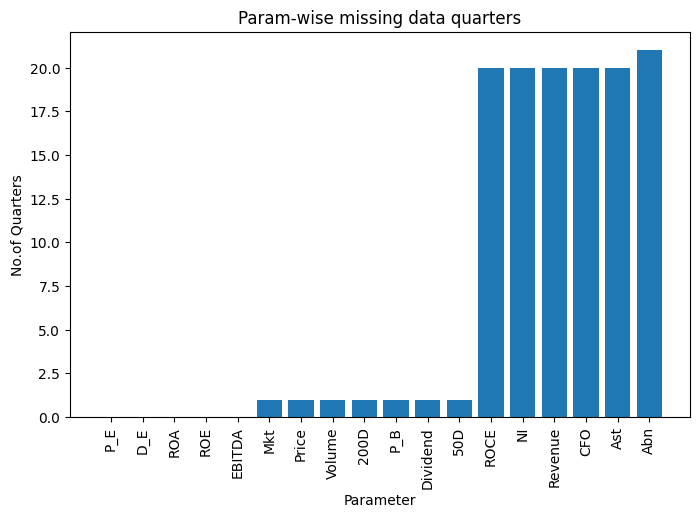

In [ ]:
param_wise_missing_qtrs_data = (df_qtr2.drop(columns=['Quarter','listing']).sum(axis=0))
param_wise_missing_qtrs_data.sort_values(ascending=True,inplace=True)
plt.figure(figsize=(8, 5))
plt.bar(height=param_wise_missing_qtrs_data,x=param_wise_missing_qtrs_data.index)
plt.xticks(rotation = 90)
plt.title(f"Param-wise missing data quarters")
plt.ylabel("No.of Quarters")
plt.xlabel("Parameter")
plt.show()

In [ ]:
df_qtr2['Quarter'] = df_qtr2['Quarter'].astype(str).apply(convert_qtr_to_date)

In [ ]:
df_qtr2['Quarter'] = pd.to_datetime(df_qtr2['Quarter'],dayfirst=True)

In [ ]:
df_qtr2['Quarter1'] = df_qtr2['Quarter'].dt.strftime('%b-%y')

In [ ]:
df_qtr3 = df_qtr2.set_index(keys=['Quarter1'])

In [ ]:
df_qtr3.drop(columns=['Quarter'],inplace=True)

In [ ]:
import seaborn as sns

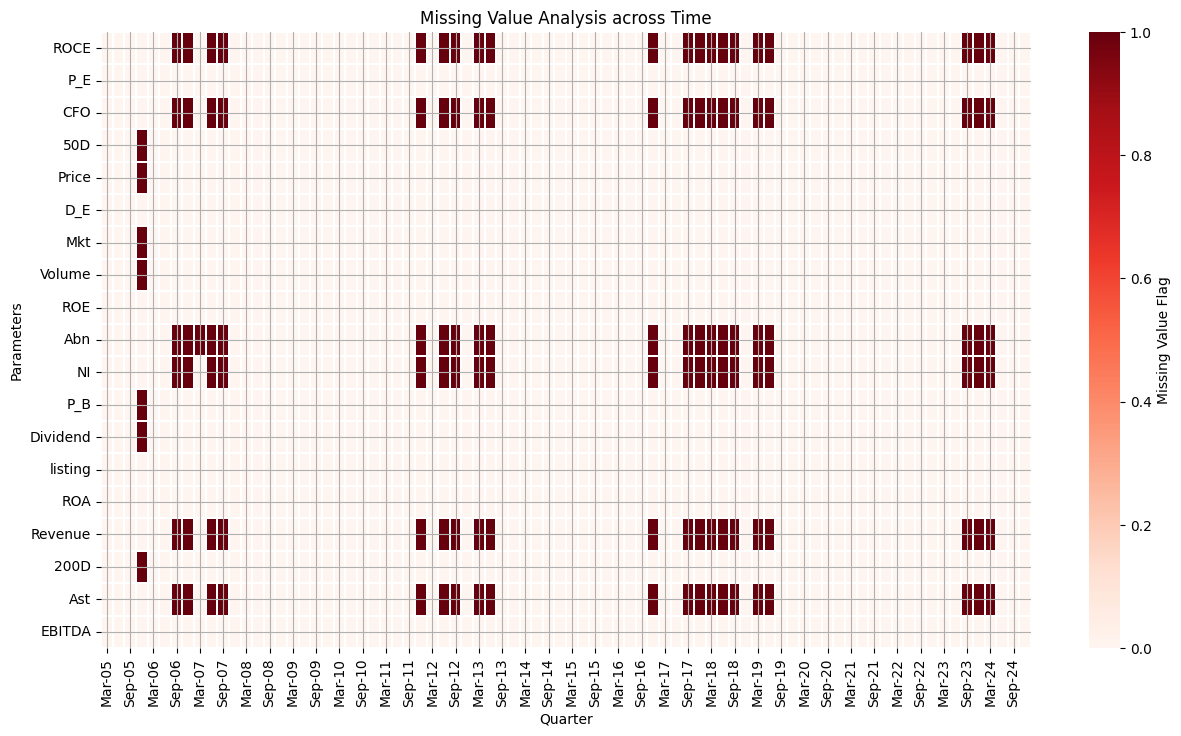

In [ ]:
plt.figure(figsize=(15, 8))
sns.heatmap(df_qtr3.T, cmap='Reds',linewidths = 0.005, cbar_kws={'label': 'Missing Value Flag'})
plt.title('Missing Value Analysis across Time')
plt.xlabel('Quarter')
plt.ylabel('Parameters')
plt.xticks(rotation=90)
plt.grid(visible=True,which='both',axis='both')
plt.show()

#### QoQ and YoY growths

In [ ]:
perc_cols = ['Revenue','NI','CFO','200D','50D','Volume','EBITDA']

In [ ]:
df_temp1 = df_stock1.parse(sheet_name='Revenue')

In [ ]:
df_temp1.head(3)

,Ticker,Revenue_Q4FY05,Revenue_Q1FY06,Revenue_Q2FY06,Revenue_Q3FY06,Revenue_Q4FY06,Revenue_Q1FY07,Revenue_Q2FY07,Revenue_Q3FY07,Revenue_Q4FY07,...,Revenue_Q2FY23,Revenue_Q3FY23,Revenue_Q4FY23,Revenue_Q1FY24,Revenue_Q2FY24,Revenue_Q3FY24,Revenue_Q4FY24,Revenue_Q1FY25,Revenue_Q2FY25,Revenue_Q3FY25
0,NSEMCAP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,RELIANCE IN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2294090.0,NaN,2129450.0,2075590.0,NaN,NaN,NaN,2317840.0,2315350.0,239986.0
2,TCS IN,21476.5996,22500.5996,25044.9004,27201.9004,37092.1,42271.9,NaN,NaN,NaN,...,553090.0,NaN,591620.0,593810.0,NaN,NaN,NaN,626130.0,642590.0,63973.0


In [ ]:
df_temp1.set_index(keys=['Ticker'],inplace=True)

In [ ]:
df_temp_qoq_growth = (df_temp1.div(df_temp1.shift(periods=1,axis=1))-1)*100
df_temp_yoy_growth = (df_temp1.div(df_temp1.shift(periods=4,axis=1))-1)*100

In [ ]:
df_temp1.head()

,Revenue_Q4FY05,Revenue_Q1FY06,Revenue_Q2FY06,Revenue_Q3FY06,Revenue_Q4FY06,Revenue_Q1FY07,Revenue_Q2FY07,Revenue_Q3FY07,Revenue_Q4FY07,Revenue_Q1FY08,...,Revenue_Q2FY23,Revenue_Q3FY23,Revenue_Q4FY23,Revenue_Q1FY24,Revenue_Q2FY24,Revenue_Q3FY24,Revenue_Q4FY24,Revenue_Q1FY25,Revenue_Q2FY25,Revenue_Q3FY25
Ticker,,,,,,,,,,,,,,,,,,,,,
NSEMCAP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RELIANCE IN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2294090.0,NaN,2129450.0,2075590.0,NaN,NaN,NaN,2317840.0,2315350.0,239986.00
TCS IN,21476.5996,22500.5996,25044.9004,27201.9004,37092.1,42271.9,NaN,NaN,NaN,NaN,...,553090.0,NaN,591620.0,593810.0,NaN,NaN,NaN,626130.0,642590.0,63973.00
HDFCB IN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,491821.0,NaN,571588.4,610212.9,NaN,NaN,NaN,1169964.9,1214567.4,112193.94
BHARTI IN,NaN,25249.0000,26960.0000,29947.0000,33956.8,38154.9,NaN,NaN,NaN,NaN,...,345268.0,NaN,360090.0,374400.0,NaN,NaN,NaN,385064.0,414733.0,45129.30


In [ ]:
df_temp_qoq_growth.head()

,Revenue_Q4FY05,Revenue_Q1FY06,Revenue_Q2FY06,Revenue_Q3FY06,Revenue_Q4FY06,Revenue_Q1FY07,Revenue_Q2FY07,Revenue_Q3FY07,Revenue_Q4FY07,Revenue_Q1FY08,...,Revenue_Q2FY23,Revenue_Q3FY23,Revenue_Q4FY23,Revenue_Q1FY24,Revenue_Q2FY24,Revenue_Q3FY24,Revenue_Q4FY24,Revenue_Q1FY25,Revenue_Q2FY25,Revenue_Q3FY25
Ticker,,,,,,,,,,,,,,,,,,,,,
NSEMCAP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RELIANCE IN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4.822371,NaN,NaN,-2.529292,NaN,NaN,NaN,NaN,-0.107428,-89.635001
TCS IN,NaN,4.76798,11.307702,8.612532,36.358488,13.964699,NaN,NaN,NaN,NaN,...,4.835286,NaN,NaN,0.370170,NaN,NaN,NaN,NaN,2.628847,-90.044507
HDFCB IN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,11.265879,NaN,NaN,6.757397,NaN,NaN,NaN,NaN,3.812294,-90.762642
BHARTI IN,NaN,NaN,6.776506,11.079377,13.389655,12.363061,NaN,NaN,NaN,NaN,...,5.249873,NaN,NaN,3.974006,NaN,NaN,NaN,NaN,7.704953,-89.118469


In [ ]:
df_temp_yoy_growth.head()

,Revenue_Q4FY05,Revenue_Q1FY06,Revenue_Q2FY06,Revenue_Q3FY06,Revenue_Q4FY06,Revenue_Q1FY07,Revenue_Q2FY07,Revenue_Q3FY07,Revenue_Q4FY07,Revenue_Q1FY08,...,Revenue_Q2FY23,Revenue_Q3FY23,Revenue_Q4FY23,Revenue_Q1FY24,Revenue_Q2FY24,Revenue_Q3FY24,Revenue_Q4FY24,Revenue_Q1FY25,Revenue_Q2FY25,Revenue_Q3FY25
Ticker,,,,,,,,,,,,,,,,,,,,,
NSEMCAP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RELIANCE IN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,36.869895,NaN,2.685955,-5.161408,NaN,NaN,NaN,11.671380,NaN,NaN
TCS IN,NaN,NaN,NaN,NaN,72.709371,87.870105,NaN,NaN,NaN,NaN,...,18.012674,NaN,16.941749,12.553546,NaN,NaN,NaN,5.442818,NaN,NaN
HDFCB IN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,18.693099,NaN,30.023328,38.049971,NaN,NaN,NaN,91.730607,NaN,NaN
BHARTI IN,NaN,NaN,NaN,NaN,NaN,51.114500,NaN,NaN,NaN,NaN,...,21.889121,NaN,14.313197,14.130335,NaN,NaN,NaN,2.848291,NaN,NaN


##### Ratios

In [ ]:
# df_ratios1 = pd.ExcelFile(r"D:\FY25-26\Quant Fund\data\Param_Wise_Qtrly_Data_PEG_EPS_PS_IC_last20Yrs.xlsx")

In [ ]:
# df_qtr = pd.DataFrame(all_qtrs,columns=['Quarter'])
# df_qtr2 = df_qtr.copy()

# for param in df_ratios1.sheet_names:
#     df_n1 = df_ratios1.parse(sheet_name=param)
#     no_data_qtrs = pd.Series((df_n1.columns)[df_n1.isna().all()])
#     if len(no_data_qtrs)!=0:
#         no_data_qtrs_list = no_data_qtrs.apply(lambda x: x[-6:])
#     else:
#         no_data_qtrs_list = []
#     df_qtr1 = df_qtr.copy()
#     df_qtr1[param] = np.where(df_qtr1['Quarter'].isin(no_data_qtrs_list),1,0)

#     # df_qtr1['Quarter'] = df_qtr1['Quarter'].apply(convert_qtr_to_date)
#     # plt.figure(figsize=(8, 5))
#     # plt.plot(df_qtr1[df_qtr1[param]==1].set_index(keys=['Quarter']))
#     # plt.xticks(rotation = 90)
#     # plt.title(f"Null Value Analysis in {param}")
#     # plt.show()

#     df_qtr2 = df_qtr2.merge(df_qtr1,on='Quarter',how='left')
# df_qtr2.head()
# param_wise_missing_qtrs_data = (df_qtr2.drop(columns=['Quarter']).sum(axis=0))
# param_wise_missing_qtrs_data.sort_values(ascending=True,inplace=True)
# plt.figure(figsize=(8, 5))
# plt.bar(height=param_wise_missing_qtrs_data,x=param_wise_missing_qtrs_data.index)
# plt.xticks(rotation = 90)
# plt.title(f"Param-wise missing data quarters")
# plt.ylabel("No.of Quarters")
# plt.xlabel("Parameter")
# plt.show()
# df_qtr2['Quarter'] = df_qtr2['Quarter'].astype(str).apply(convert_qtr_to_date)
# df_qtr2['Quarter'] = pd.to_datetime(df_qtr2['Quarter'],dayfirst=True)
# df_qtr2['Quarter1'] = df_qtr2['Quarter'].dt.strftime('%b-%y')
# df_qtr3 = df_qtr2.set_index(keys=['Quarter1'])
# df_qtr3.drop(columns=['Quarter'],inplace=True)
# import seaborn as sns
# plt.figure(figsize=(15, 8))
# sns.heatmap(df_qtr3.T, cmap='Reds',linewidths = 0.005, cbar_kws={'label': 'Missing Value Flag'})
# plt.title('Missing Value Analysis across Time')
# plt.xlabel('Quarter')
# plt.ylabel('Parameters')
# plt.xticks(rotation=90)
# plt.grid(visible=True,which='both',axis='both')
# plt.show()

In [ ]:
 = pd.read_excel()